<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/11_Vulnerability_Software_Supply_Chain_Attacks/QLSTM_VulnerabilityDetection_Akter2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QLSTM for source-code vulnerability detection: Akter, Shahriar and Bhuiya (2023) step by step

**Paper.** M. S. Akter, H. Shahriar, Z. A. Bhuiya, *Automated Vulnerability Detection in Source Code Using Quantum Natural Language Processing*, arXiv preprint 2303.07525 (2023). [arxiv.org/abs/2303.07525](https://arxiv.org/abs/2303.07525).

**What this notebook does.** A C/C++ function is just text: a sequence of *words* (keywords, names, operators). The paper treats the detection of a buffer-overflow weakness (CWE-119) as a **natural-language-processing** problem. It (1) cuts every function into tokens, (2) represents every token either by a plain number ("basic representation") or by a learned word vector (**GloVe + fastText**, "semantic and syntactic representation"), and (3) reads the token sequence with an **LSTM** (a recurrent network with memory) or with its quantum version, the **QLSTM**, in which the small neural networks inside the LSTM cell are replaced by **variational quantum circuits**. The notebook rebuilds all of this on a simulator, explains every step in plain language, trains matched classical LSTMs and classical machine-learning models on exactly the same inputs, re-draws the paper's Tables 1 and 2 and its sine-wave experiment (Fig. 7), and ends with an honest claim-by-claim comparison with the paper.

**How to run.** Open in Google Colab (the badge above), choose a *CPU* runtime and use *Runtime -> Run all*. The notebook is shipped with `FAST_MODE = False` (the larger run; about 50 minutes on one CPU thread, executed here); with `FAST_MODE = True` in the configuration cell it needs about 10 to 15 minutes. The data (Draper VDISC, about 320 MB in three files) are downloaded once, reduced to a small sample of about 15 MB and the big files are deleted again. If Colab asks for a session restart after the install cell, accept it and run again from the next cell.

**What you get at the end.** Plots of the real source-code data, the drawn quantum circuit, loss curves, the paper's Tables 1 and 2 and Fig. 7 re-computed, and a verdict ("reproduced", "not reached", "exceeded", "cannot be checked") for each claim.

## The paper in one page

* **Problem.** Security weaknesses hidden in source code (here: CWE-119, "improper restriction of operations within the bounds of a memory buffer", i.e. buffer overflows) are found today mostly by rule-based static analysers that have many false alarms. The paper asks whether a learned model that reads the *function text* can do better, and whether a quantum recurrent network helps.
* **Decision.** Binary, per C/C++ function: vulnerable (1) or not vulnerable (0). Only the **balanced** part of the data is used "to avoid under- or over-fitting".
* **Method (Fig. 1).** Source code -> tokenisation (Keras `Tokenizer`, padding) -> either *basic* number sequence or *GloVe + fastText* word vectors -> **LSTM** (TensorFlow, 50 hidden units, 123,301 parameters) or **QLSTM** (PennyLane, 6 variational circuits of 4 qubits and depth 2, 122,876 parameters) -> accuracy, precision, recall, F1 and execution time.
* **QLSTM (Section 3.3, Figs. 4-6).** The LSTM gates are variational quantum circuits (after Chen, Yoo and Fang, ICASSP 2022): `i_t = sigmoid(VQC2(v_t))`, `C'_t = tanh(VQC3(v_t))`, `c_t = f_t * c_(t-1) + i_t * C'_t`, `o_t = sigmoid(VQC4(v_t))`, `h_t = sigmoid(VQC5(o_t * tanh(c_t)))`, `y_t = VQC6(o_t * tanh(c_t))` (VQC1 is the forget gate `f_t`). Each circuit has three parts: data encoding, variational layer, measurement. Two extra parameters scale the final output.
* **Data.** Draper VDISC (Russell et al. 2018): over a million C/C++ functions mined from the SATE IV Juliet suite, the Debian distribution and GitHub, labelled by static analysers, with train / validation / test folders. The paper uses the CWE-119 label.
* **Claims checked here.** Table 1 (LSTM 0.90 / QLSTM 0.94 accuracy with the basic representation), Table 2 (LSTM 0.92 / QLSTM 0.95 with GloVe + fastText), the execution times (the QLSTM is about 2 to 3 times faster), the statement that embeddings improve accuracy but cost time, the headline "accuracy 95 %, precision 97 %, recall 98 %, F1 99 %", and the sine-wave experiment of Fig. 7 ("QLSTM learns better than LSTM").

## What follows the paper and what had to be chosen

The paper gives no code, no sample sizes, no sequence length, no optimiser, batch size or number of epochs for the classification experiment, no circuit gate list in text (Figs. 4-5 are images), and no description of the embedding training. Everything not given is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Data | Russell et al. 2018 (Draper VDISC): "millions" of C/C++ functions, CWE-119 label, balanced portion, train / validation / test folders (the link given, cwe.mitre.org, is only the CWE definition page) | The public Hugging Face mirror `claudios/Draper` of Draper VDISC: 1,019,471 / 127,476 / 127,419 functions in train / validation / test, with the five static-analyser flags `CWE-119, CWE-120, CWE-469, CWE-476, CWE-other`. Files read: train shard 1 of 2 (509,736 functions), validation, test. No token is needed (public); a Hugging Face token is resolved from the environment or Colab Secrets only if the reader's mirror requires one |
| Classes | vulnerable vs non-vulnerable, "almost equal" numbers | positive = flag `CWE-119`; negative = a function with **no** flag at all (clean); equal numbers of both, drawn at random with `SEED` |
| Sample sizes | not given | limited by the CPU simulator: `TRAIN_PER_CLASS`, `VAL_PER_CLASS`, `TEST_PER_CLASS` in the configuration cell |
| Pre-processing | "dependency analysis, program slicing, tokenization and serialization" are named in the introduction, but Section 3 describes only the Keras tokenizer, sequences and padding | comments removed, a regular-expression lexer for C (identifiers, operators, brackets), string / character / number literals replaced by `<str>`, `<chr>`, `<num>` (0 and 1 kept); **no** slicing or dependency analysis (not described); exact duplicates removed across splits |
| Basic representation | "each word is represented by a number" (Keras tokenizer ids), normalised | the rank of the token in the training vocabulary divided by the vocabulary size: one number per token |
| Semantic and syntactic representation | GloVe and fastText embeddings (pre-trained or trained on the code corpus is not stated) | **both trained here from scratch** on unlabelled functions of the training split (pre-trained GloVe / fastText vectors are made for English and are huge): GloVe (co-occurrence matrix, weighted least squares, 16 dimensions) and fastText (skip-gram with negative sampling and sub-word 3-6-grams, 16 dimensions), written in PyTorch, concatenated to 32 numbers per token |
| Sequence length | not given | first `MAXLEN` tokens of each function, shorter ones padded in front with zeros (the Keras default); keeping the *first* tokens was chosen on a validation split |
| Classical LSTM | TensorFlow, 50 hidden units, a single output, 123,301 parameters | PyTorch `LSTM` with 50 hidden units and one sigmoid output (parameter count printed); plus an LSTM whose parameter count matches the QLSTM |
| QLSTM | PennyLane simulator; 6 VQCs of 4 qubits, depth 2; 2 scaling parameters; 122,876 parameters | the same: 6 VQCs, 4 qubits, depth 2, a 2-parameter scale; our parameter count is **far smaller** because the paper's number evidently includes layers it does not describe (for instance a trainable embedding layer) |
| Circuit | Fig. 5: encoding, variational layer, measurement | H, then RY(arctan x) and RZ(arctan x^2) encoding, then 2 layers of CNOT ladder + trainable `Rot` gates on every qubit, then Pauli-Z expectations (the circuit of Chen et al.) |
| Optimiser, epochs, batch | not given for classification (30 epochs for the sine function) | Adam, learning rate 0.01, batch 64, epochs set in the configuration cell; 30 epochs for the sine function |
| Execution time | 40 min vs 14 min (Table 1), 42 min vs 19 min (Table 2), machine not stated | wall-clock seconds of training + prediction on this CPU, with a state-vector simulator; **not comparable** with the paper's minutes |
| Sine experiment (Fig. 7) | LSTM vs QLSTM, 30 epochs, input and sizes not given | next-value prediction of `sin(x)` from the previous 4 values, 30 epochs, matched models |

## 0. Setup

Colab already ships NumPy, pandas, SciPy, scikit-learn, matplotlib, PyTorch and pyarrow. We add PennyLane, the framework the paper used for the quantum circuit, and `huggingface_hub` for the data download. The cell does nothing when everything is already installed (for example on a local machine). If Colab asks you to restart the session, accept and run again from the next cell.

In [1]:
# Colab already ships numpy, pandas, scipy, scikit-learn, matplotlib, torch and pyarrow. We add PennyLane (pinned to the tested version).
# The cell does nothing when PennyLane is already available (for example on a local machine).
import sys, importlib.util, subprocess
IN_COLAB = "google.colab" in sys.modules
need = [m for m in ("pennylane", "huggingface_hub", "pyarrow", "torch", "scipy") if importlib.util.find_spec(m) is None]
if IN_COLAB or need:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "huggingface_hub", "pyarrow", "requests"], check=True)
    print("Installed pennylane==0.45.1 (and missing helpers). If Colab asks you to restart the session, accept and run again from the next cell.")
else:
    print("PennyLane, PyTorch, pyarrow and huggingface_hub already available, nothing to install.")

PennyLane, PyTorch, pyarrow and huggingface_hub already available, nothing to install.


The **configuration cell** holds every tunable constant. `FAST_MODE = True` shrinks the sample sizes, the token sequences, the number of epochs and the number of seeds so that the notebook runs in about 10 to 15 minutes; `FAST_MODE = False` (the value shipped, executed in about 50 minutes) is the larger run (budgets in the cell). No quantum-hardware token is needed because the paper used a simulator (`IBM_TOKEN` is kept for the project convention and is not used).

In [2]:
# ------------------------------- configuration: every tunable constant lives here -------------------------------
SEED = 42
FAST_MODE = False       # True: about 10 minute class demo. False: larger samples, longer sequences, more epochs and seeds (budgets below).
DATA_DIR = "vdisc_data"          # cache folder: the reduced sample (about 15 MB) is stored here; the big downloads are deleted again
LOCAL_POOL = ""                  # optional: path of an uploaded copy of draper_pool.parquet (see the data section)
IBM_TOKEN = ""                   # not used: the paper ran a simulator only (kept for the convention)

HF_REPO = "claudios/Draper"      # public Hugging Face mirror of Draper VDISC (Russell et al. 2018)
HF_FILES = {"train": "data/train-00000-of-00002.parquet",       # CHOICE: first of the two train shards (509,736 of 1,019,471 functions)
            "validation": "data/validation-00000-of-00001.parquet",
            "test": "data/test-00000-of-00001.parquet"}
CWE_COLS = ["CWE-119", "CWE-120", "CWE-469", "CWE-476", "CWE-other"]     # the five static-analyser flags of VDISC

# --- constants from the paper ---
N_QUBITS = 4           # paper Section 4: each VQC has 4 qubits
Q_DEPTH = 2            # paper Section 4: 2 depths in each variational layer
N_VQC = 6              # paper Section 4: 6 VQCs per QLSTM cell
LSTM_UNITS = 50        # paper Section 4: classical LSTM with 50 hidden units
SINE_EPOCHS = 30       # paper Fig. 7: 30 epochs

# --- choices the paper leaves open (marked # CHOICE: where they are used) ---
# size of the sample that is cached from the three VDISC files (per class, balanced); the cache is the same for both modes
POOL = dict(train=4000, validation=1000, test=2000)     # CHOICE: functions per class kept from each file
NATURAL_N = 20000      # CHOICE: random functions (natural class mix) of the train shard, used only as unlabelled text to learn the word vectors
MAX_CHARS = 3000       # CHOICE: functions are cut at 3000 characters before tokenising (the VDISC functions have at most about 500 tokens anyway)
VOCAB = 3000           # CHOICE: vocabulary size (index 0 = padding, 1 = unknown token)
EMB_DIM = 16           # CHOICE: dimensions of each of the two word-vector tables (GloVe 16 + fastText 16 = 32 numbers per token)
Q_LR = 0.01            # CHOICE: Adam learning rate (not given for classification)
Q_BATCH = 64           # CHOICE: mini-batch size (not given)
Q_HIDDEN = 8           # CHOICE: hidden size of the QLSTM and of the size-matched classical LSTM
SINE_STEPS = 4         # CHOICE: the sine experiment predicts the next value from the previous 4 values
SVC_MAX = 4000         # CHOICE: the RBF SVC is trained on at most this many rows

if FAST_MODE:
    TRAIN_POOL, TRAIN_PER_CLASS, VAL_PER_CLASS, TEST_PER_CLASS = 500, 300, 100, 500
    CORPUS_N, MAXLEN, EPOCHS, N_SEEDS, RF_TREES = 6000, 32, 8, 1, 100
    GLOVE_EPOCHS, FT_EPOCHS, FT_PAIRS = 12, 3, 400_000
else:
    # full run: about 60-90 minutes on one CPU thread (the paper's setting, all functions and an unknown number of epochs, is out of reach of a state-vector simulator)
    TRAIN_POOL, TRAIN_PER_CLASS, VAL_PER_CLASS, TEST_PER_CLASS = 2000, 1000, 300, 1500
    CORPUS_N, MAXLEN, EPOCHS, N_SEEDS, RF_TREES = 12000, 48, 15, 2, 300
    GLOVE_EPOCHS, FT_EPOCHS, FT_PAIRS = 20, 4, 1_500_000

In [3]:
import os, io, re, time, math, json, zlib, shutil, collections, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, scipy.sparse as sp
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
import sklearn
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
warnings.filterwarnings("ignore")

# Hugging Face token: only needed for gated datasets (this mirror is public). Never printed, never written to a file.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

def set_seed(s):
    s = int(s); np.random.seed(s % (2**32 - 1)); torch.manual_seed(s)

set_seed(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(1)
os.makedirs(DATA_DIR, exist_ok=True)
print("numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__, "| torch", torch.__version__, "| pennylane", qml.__version__)
print("FAST_MODE =", FAST_MODE, "| train/val/test functions per class =", TRAIN_PER_CLASS, VAL_PER_CLASS, TEST_PER_CLASS,
      "| MAXLEN =", MAXLEN, "| epochs =", EPOCHS, "| seeds =", N_SEEDS)

numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1 | torch 2.14.1+cpu | pennylane 0.45.1
FAST_MODE = False | train/val/test functions per class = 1000 300 1500 | MAXLEN = 48 | epochs = 15 | seeds = 2


## 1. Data: Draper VDISC, millions of real C/C++ functions

The paper uses the dataset of Russell et al. (ICMLA 2018), usually called **Draper VDISC**: C and C++ functions collected from the SATE IV Juliet test suite (synthetic), the Debian Linux distribution and public GitHub repositories. Each function carries **five flags** set by three static analysers (Clang, Cppcheck, Flawfinder): `CWE-119` (improper restriction of operations within the bounds of a memory buffer), `CWE-120` (classic buffer copy without size check), `CWE-469` (use of pointer subtraction to determine size), `CWE-476` (NULL pointer dereference) and `CWE-other`. A function can carry several flags or none. The paper uses `CWE-119` as the vulnerability.

The three files are large (214 + 54 + 53 MB). The cell downloads them **one at a time**, reads the five label columns, draws a random sample (balanced `CWE-119` vs *clean*, i.e. no flag at all, plus a natural-mix sample of the train file that serves as unlabelled text for the word vectors), stores the sample as one small Parquet file in `DATA_DIR`, records the exact class counts of the three complete files in `draper_counts.json`, and **deletes each big file immediately**. The sample is the same for `FAST_MODE` and the full run; it is only drawn once. If the Hugging Face mirror is not reachable you can upload a copy of `draper_pool.parquet` and set `LOCAL_POOL`.

In [4]:
POOL_FILE = os.path.join(DATA_DIR, "draper_pool.parquet")
COUNT_FILE = os.path.join(DATA_DIR, "draper_counts.json")
META_FILE = os.path.join(DATA_DIR, "draper_pool_meta.json")
META = dict(repo=HF_REPO, files=HF_FILES, pool=POOL, natural=NATURAL_N, max_chars=MAX_CHARS, seed=SEED)

def build_pool():
    # Download each VDISC file once, keep a random sample of its functions + the exact flag counts of the whole file, delete the file.
    import pyarrow.parquet as pq
    from huggingface_hub import hf_hub_download
    hf_cache = os.path.join(DATA_DIR, "hf_cache"); rs = np.random.default_rng(SEED); counts, rows = {}, []
    for split, fn in HF_FILES.items():
        t0 = time.time()
        path = hf_hub_download(HF_REPO, fn, repo_type="dataset", token=HF_TOKEN, cache_dir=hf_cache)
        print(f"{split}: downloaded {os.path.getsize(path)/1e6:.0f} MB in {time.time()-t0:.0f}s", flush=True)
        pf = pq.ParquetFile(path)
        lab = pf.read(columns=CWE_COLS).to_pandas().astype(bool)                     # the five flags of every function of the file
        clean = ~lab.any(axis=1)
        counts[split] = dict(n=int(len(lab)), clean=int(clean.sum()), **{c: int(lab[c].sum()) for c in CWE_COLS})
        pos = np.flatnonzero(lab["CWE-119"].to_numpy()); neg = np.flatnonzero(clean.to_numpy()); sel = {}
        for i in rs.choice(pos, size=min(POOL[split], len(pos)), replace=False): sel[int(i)] = "pos"      # CWE-119 flagged
        for i in rs.choice(neg, size=min(POOL[split], len(neg)), replace=False): sel[int(i)] = "neg"      # no flag at all
        if split == "train":
            for i in rs.choice(len(lab), size=NATURAL_N, replace=False): sel.setdefault(int(i), "nat")    # natural mix (unlabelled text for embeddings)
        got, off = {}, 0
        for b in pf.iter_batches(batch_size=20000, columns=["functionSource"]):
            col = b.column(0).to_pylist()
            for j, s in enumerate(col):
                if off + j in sel: got[off + j] = s[:MAX_CHARS]
            off += len(col)
        for gi, role in sel.items():
            rows.append(dict(split=split, role=role, src=got[gi], **{c: bool(lab.iloc[gi][c]) for c in CWE_COLS}))
        del pf, lab
        shutil.rmtree(hf_cache, ignore_errors=True)                                  # delete the big file right away
        print(f"  {split}: kept {len(sel)} functions, big file deleted ({time.time()-t0:.0f}s)", flush=True)
    pd.DataFrame(rows).to_parquet(POOL_FILE, index=False)
    json.dump(counts, open(COUNT_FILE, "w"), indent=1); json.dump(META, open(META_FILE, "w"), indent=1)

def cache_ok():
    try: return all(os.path.exists(p) for p in (POOL_FILE, COUNT_FILE, META_FILE)) and json.load(open(META_FILE)) == META
    except Exception: return False

if LOCAL_POOL and os.path.exists(LOCAL_POOL):
    POOL_FILE = LOCAL_POOL; assert os.path.exists(COUNT_FILE), "LOCAL_POOL also needs draper_counts.json in DATA_DIR"
elif not cache_ok():
    build_pool()
else:
    print("using the cached sample in", DATA_DIR)
pool = pd.read_parquet(POOL_FILE)
counts = json.load(open(COUNT_FILE))
print("\nsample stored in", POOL_FILE, f"({os.path.getsize(POOL_FILE)/1e6:.1f} MB):", pool.shape)
print(pool.groupby(["split", "role"]).size().rename("functions").to_string())
print("\nexact flag counts of the three complete VDISC files used (all functions, not the sample):")
print(pd.DataFrame(counts).T.to_string())

using the cached sample in

 vdisc_data



sample stored in vdisc_data\draper_pool.parquet (14.7 MB): (33711, 8)
split       role
test        neg      2000
            pos      2000
train       nat     19711
            neg      4000
            pos      4000
validation  neg      1000
            pos      1000

exact flag counts of the three complete VDISC files used (all functions, not the sample):
                 n   clean  CWE-119  CWE-120  CWE-469  CWE-476  CWE-other
train       509736  476821     9617    18968     1000     4873      13894
validation  127476  119222     2419     4750      252     1208       3579
test        127419  119166     2452     4891      278     1192       3490


## 2. From source text to tokens, and the splits

A neural network cannot read text, so every function is first cut into **tokens**, the "words" of a programming language: keywords (`if`, `for`, `char`), identifiers (`strcpy`, `buf`), operators (`=`, `->`, `==`), brackets and numbers. The steps, in this order:

1. delete the comments (`/* ... */`, `// ...`);
2. split with a small regular-expression lexer for C; a string literal becomes `<str>`, a character literal `<chr>`, a number other than 0 and 1 becomes `<num>` (otherwise the vocabulary would explode and the model could memorise constants);
3. **remove exact duplicates**: two functions with identical token sequences are kept once, and a function that appears in the training sample is deleted from the validation and test samples (so no test function has an exact twin in training);
4. the **vocabulary** is the `VOCAB - 2` most frequent tokens of the *training* functions (index 0 = padding, 1 = unknown); everything else becomes "unknown";
5. a function becomes a list of `MAXLEN` token numbers: the first `MAXLEN` tokens, shorter functions padded with zeros **in front** (the Keras default for `pad_sequences`).

Nothing is fitted on validation or test functions. The balanced samples are drawn with `SEED`; each seed later re-draws its own `TRAIN_PER_CLASS` training functions per class from the `TRAIN_POOL` per class kept here.

In [5]:
CMT = re.compile(r"/\*.*?\*/|//[^\n]*", re.S)
TOK = re.compile(r'"(?:\\.|[^"\\\n])*"|\'(?:\\.|[^\'\\\n])*\'|[A-Za-z_]\w*|\d[\w.]*|==|!=|<=|>=|&&|\|\||->|\+\+|--|<<|>>|\+=|-=|\*=|/=|[-+*/%=<>!&|^~?:;,.(){}\[\]#]')
def tokenize(s):
    out = []
    for t in TOK.findall(CMT.sub(" ", s)):
        c = t[0]
        if c == '"': out.append("<str>")                                   # CHOICE: literals are normalised
        elif c == "'": out.append("<chr>")
        elif c.isdigit(): out.append(t if t in ("0", "1") else "<num>")
        else: out.append(t)
    return out

# ---- choose the functions of this run (the cached sample is larger than FAST_MODE needs) ----
rs = np.random.default_rng(SEED)
def take(split, role, n):
    idx = pool.index[(pool.split == split) & (pool.role == role)].to_numpy()
    return rs.choice(idx, size=min(n, len(idx)), replace=False)
chosen = {"train": np.concatenate([take("train", "pos", TRAIN_POOL), take("train", "neg", TRAIN_POOL)]),
          "val": np.concatenate([take("validation", "pos", VAL_PER_CLASS), take("validation", "neg", VAL_PER_CLASS)]),
          "test": np.concatenate([take("test", "pos", TEST_PER_CLASS), take("test", "neg", TEST_PER_CLASS)]),
          "corpus": take("train", "nat", CORPUS_N)}

t0 = time.time(); tok_cache = {}; seen = set(); D = {}
for part in ("train", "val", "test", "corpus"):                           # order = priority when two functions are identical
    sub = pool.loc[chosen[part]].copy(); sub["toks"] = sub.src.map(tokenize); sub["h"] = sub.toks.map(lambda t: hash(tuple(t)))
    n0 = len(sub); sub = sub[(sub.toks.map(len) >= 5) & ~sub.h.duplicated()]
    sub = sub[~sub.h.isin(seen)]                                           # also keeps the unlabelled corpus free of validation / test twins
    if part != "corpus": seen |= set(sub.h)
    D[part] = sub.reset_index(drop=True); print(f"{part:7s}: {n0} functions drawn, {len(D[part])} kept (exact duplicates / near-empty removed: {n0 - len(D[part])})")
for part in ("train", "val", "test"):
    D[part]["y"] = (D[part].role == "pos").astype(int)
print(f"tokenised in {time.time()-t0:.0f}s")

# ---- vocabulary from the training functions + the unlabelled corpus (never validation / test) ----
cnt = collections.Counter(t for ts in list(D["train"].toks) + list(D["corpus"].toks) for t in ts)
itos = ["<pad>", "<unk>"] + [w for w, _ in cnt.most_common(VOCAB - 2)]; stoi = {w: i for i, w in enumerate(itos)}
cov = sum(cnt[w] for w in itos[2:]) / sum(cnt.values())
print(f"vocabulary {len(itos)} tokens, covers {cov*100:.1f}% of all training tokens; most frequent:", itos[2:22])

def to_ids(toks): return np.array([stoi.get(t, 1) for t in toks], dtype=np.int64)
for part in D: D[part]["ids"] = D[part].toks.map(to_ids)
tr_len = D["train"].ids.map(len)
print(f"tokens per training function: median {tr_len.median():.0f}, mean {tr_len.mean():.0f}; share longer than MAXLEN={MAXLEN}: {(tr_len > MAXLEN).mean()*100:.0f}%")

def pad(seqs, T=None):
    T = T or MAXLEN; out = np.zeros((len(seqs), T), dtype=np.int64)
    for i, s in enumerate(seqs):
        s = s[:T]; out[i, T - len(s):] = s                                  # CHOICE: keep the FIRST T tokens, pad in FRONT (Keras default padding)
    return out
IDS = {p: pad(D[p].ids) for p in ("train", "val", "test")}
Y = {p: D[p].y.to_numpy() for p in ("train", "val", "test")}
print({p: (IDS[p].shape, int(Y[p].sum()), int((1 - Y[p]).sum())) for p in IDS}, "(shape, vulnerable, clean)")

train  : 4000 functions drawn, 4000 kept (exact duplicates / near-empty removed: 0)


val    : 600 functions drawn, 600 kept (exact duplicates / near-empty removed: 0)


test   : 3000 functions drawn, 3000 kept (exact duplicates / near-empty removed: 0)


corpus : 12000 functions drawn, 12000 kept (exact duplicates / near-empty removed: 0)
tokenised in 10s


vocabulary 3000 tokens, covers 84.8% of all training tokens; most frequent: ['(', ')', ';', ',', '=', '->', '*', '{', '}', 'if', '0', '<str>', '.', '[', ']', 'return', '<num>', '&', ':', 'i']


tokens per training function: median 155, mean 183; share longer than MAXLEN=48: 93%
{'train': ((4000, 48), 2000, 2000), 'val': ((600, 48), 300, 300), 'test': ((3000, 48), 1500, 1500)} (shape, vulnerable, clean)


## 3. Two input representations: a number per token, or a word vector (GloVe + fastText)

**Basic representation (Table 1).** Every token is replaced by its number in the vocabulary, divided by the vocabulary size so that the numbers lie in [0, 1] (the paper normalises its numerical values). One number per token: a function of `MAXLEN` tokens becomes a sequence of `MAXLEN` numbers. The number says *how frequent* the token is, nothing else.

**Semantic and syntactic representation (Table 2).** A **word vector** places every token in a space in which tokens used in similar contexts are close. The paper uses two classic algorithms:

* **GloVe** counts how often two tokens appear near each other in the whole corpus (a co-occurrence matrix, nearer pairs count more) and fits vectors so that the dot product of two vectors matches the logarithm of their co-occurrence count (weighted least squares).
* **fastText** learns vectors with the skip-gram idea (predict the neighbours of a token) but builds the vector of a token from its **sub-words**, the character 3- to 6-grams of `<token>` (for example `<st`, `str`, `trc`, `rcp`, `cpy`, `py>`), so that `strcpy`, `strncpy` and `strcat` share parts. It is trained with negative sampling (the model must tell true neighbours from random tokens).

Pre-trained GloVe / fastText vectors are made from English text (and are 1 GB or more); source code has its own vocabulary. We therefore **train both from scratch on unlabelled functions of the training split** (own PyTorch code, no extra package), concatenate the two vectors (16 + 16 numbers), standardise every column, and use the result as the input of the networks. The tables are frozen during classification, as pre-trained embeddings would be.

In [6]:
V = len(itos)
corpus_ids = [a for a in list(D["corpus"].ids) + list(D["train"].ids)]          # unlabelled text: labels are never used here
freq = np.bincount(np.concatenate(corpus_ids), minlength=V).astype(np.float64)
print(f"embedding corpus: {len(corpus_ids)} functions, {int(freq.sum()):,} tokens")

def train_glove(seqs, dim, epochs, seed, window=5, xmax=100.0, alpha=0.75, lr=0.05, batch=65536):
    # GloVe: weighted least squares on log co-occurrence counts (Pennington et al. 2014); distance-weighted window counts
    r, c, v = [], [], []
    for s in seqs:
        for d in range(1, window + 1):
            if len(s) > d:
                a, b = s[:-d], s[d:]; r += [a, b]; c += [b, a]; v += [np.full(len(a), 1.0 / d)] * 2
    M = sp.coo_matrix((np.concatenate(v), (np.concatenate(r), np.concatenate(c))), shape=(V, V)).tocsr().tocoo()
    i, j, x = (torch.as_tensor(M.row, dtype=torch.long), torch.as_tensor(M.col, dtype=torch.long), torch.as_tensor(M.data, dtype=torch.float32))
    logx, fw = torch.log(x), torch.clamp((x / xmax) ** alpha, max=1.0)
    g = torch.Generator().manual_seed(seed)
    W, Wt = nn.Parameter((torch.rand(V, dim, generator=g) - .5) / dim), nn.Parameter((torch.rand(V, dim, generator=g) - .5) / dim)
    b, bt = nn.Parameter(torch.zeros(V)), nn.Parameter(torch.zeros(V)); opt = torch.optim.Adam([W, Wt, b, bt], lr=lr); losses = []
    for ep in range(epochs):
        perm = torch.randperm(len(x), generator=g); tot = 0.0
        for k in range(0, len(x), batch):
            ii = perm[k:k + batch]; opt.zero_grad()
            loss = (fw[ii] * ((W[i[ii]] * Wt[j[ii]]).sum(1) + b[i[ii]] + bt[j[ii]] - logx[ii]) ** 2).sum() / len(ii); loss.backward(); opt.step(); tot += float(loss) * len(ii)
        losses.append(tot / len(x))
    return (W + Wt).detach(), losses, len(x)

def subword_ids(word, buckets, kmax, nmin=3, nmax=6):
    # fastText sub-words: character n-grams of "<word>" hashed into `buckets` slots (zlib.crc32 is stable across runs)
    w = "<" + word + ">"; out = [zlib.crc32(w[k:k + n].encode()) % buckets for n in range(nmin, nmax + 1) for k in range(len(w) - n + 1) if w[k:k + n] != w]
    return out[:kmax]

def train_fasttext(seqs, dim, epochs, seed, n_pairs, window=5, neg=5, buckets=20000, kmax=40, t_sub=1e-3, lr=0.02, batch=8192):
    # fastText skip-gram with negative sampling; the input vector of a word = mean(word vector, its sub-word vectors)
    pad_idx = V + buckets; NG = np.full((V, kmax + 1), pad_idx, dtype=np.int64)
    for w in range(2, V):
        ids = [w] + [V + h for h in subword_ids(itos[w], buckets, kmax)]; NG[w, :len(ids)] = ids
    NG[0, 0] = 0; NG[1, 0] = 1; NG = torch.as_tensor(NG)
    g = torch.Generator().manual_seed(seed); rs_ = np.random.default_rng(seed)
    emb_in = nn.EmbeddingBag(V + buckets + 1, dim, mode="mean", padding_idx=pad_idx); emb_out = nn.Embedding(V, dim)
    with torch.no_grad(): emb_in.weight.uniform_(-1 / dim, 1 / dim); emb_in.weight[pad_idx] = 0; emb_out.weight.zero_()
    f = freq / freq.sum(); keep = np.minimum(1.0, np.sqrt(t_sub / np.maximum(f, 1e-12)) + t_sub / np.maximum(f, 1e-12))     # word2vec frequent-token sub-sampling
    noise = torch.as_tensor(f ** 0.75 / (f ** 0.75).sum(), dtype=torch.float32); opt = torch.optim.Adam(list(emb_in.parameters()) + list(emb_out.parameters()), lr=lr); losses = []
    for ep in range(epochs):
        cs, os_ = [], []
        for s in seqs:
            s = s[rs_.random(len(s)) < keep[s]]
            for d in range(1, window + 1):
                if len(s) > d: cs += [s[:-d], s[d:]]; os_ += [s[d:], s[:-d]]
        cs, os_ = np.concatenate(cs), np.concatenate(os_); sel = rs_.choice(len(cs), size=min(n_pairs, len(cs)), replace=False)
        cs, os_ = torch.as_tensor(cs[sel]), torch.as_tensor(os_[sel]); tot = 0.0
        for k in range(0, len(cs), batch):
            c_, o_ = cs[k:k + batch], os_[k:k + batch]; opt.zero_grad()
            u = emb_in(NG[c_]); pos = F.logsigmoid((u * emb_out(o_)).sum(1))
            nn_ = torch.multinomial(noise, len(c_) * neg, replacement=True, generator=g).view(len(c_), neg)
            ng = F.logsigmoid(-(u.unsqueeze(1) * emb_out(nn_)).sum(2)).sum(1); loss = -(pos + ng).mean(); loss.backward(); opt.step(); tot += float(loss) * len(c_)
        losses.append(tot / len(cs))
    with torch.no_grad(): vec = emb_in(NG).detach()
    return vec, losses

t0 = time.time(); GL, gl_loss, n_cooc = train_glove(corpus_ids, EMB_DIM, GLOVE_EPOCHS, SEED)
print(f"GloVe: {n_cooc:,} non-zero co-occurrence pairs, loss {gl_loss[0]:.3f} -> {gl_loss[-1]:.3f} in {GLOVE_EPOCHS} epochs ({time.time()-t0:.0f}s)")
t0 = time.time(); FT, ft_loss = train_fasttext(corpus_ids, EMB_DIM, FT_EPOCHS, SEED, FT_PAIRS)
print(f"fastText: loss {ft_loss[0]:.3f} -> {ft_loss[-1]:.3f} in {FT_EPOCHS} epochs of {FT_PAIRS:,} pairs ({time.time()-t0:.0f}s)")

# sanity check of the learned vectors: nearest neighbours (cosine) of a few tokens, for each table
def neighbours(E, w, k=6):
    En = E / (E.norm(dim=1, keepdim=True) + 1e-9); sim = En[2:] @ En[stoi[w]]; top = torch.argsort(-sim)[:k + 1] + 2
    return [itos[t] for t in top.tolist() if t != stoi[w]][:k]
for w in [w for w in ("strcpy", "malloc", "if", "int", "[", "sizeof") if w in stoi]:
    print(f"  {w:8s} GloVe: {neighbours(GL, w)}\n  {'':8s} fastText: {neighbours(FT, w)}")

# standardise each column with the token-frequency weighted mean / std of the training corpus; padding stays exactly 0
def standardise(E):
    w_ = torch.as_tensor(freq[2:] / freq[2:].sum(), dtype=torch.float32)[:, None]; mu = (E[2:] * w_).sum(0); sd = torch.sqrt(((E[2:] - mu) ** 2 * w_).sum(0)) + 1e-6
    out = (E - mu) / sd; out[0] = 0.0; return out
EMB_TABLE = torch.cat([standardise(GL), standardise(FT)], 1).float().numpy()           # (V, 2*EMB_DIM)
D_EMB = EMB_TABLE.shape[1]

def basic_repr(ids): return (ids.astype(np.float32) / V)[:, :, None]                    # (N, T, 1): token rank / vocabulary size
def emb_repr(ids): return EMB_TABLE[ids].astype(np.float32)                              # (N, T, 32)
# inputs of the networks: "basic" = the token numbers themselves (a trainable embedding layer inside the network turns them into vectors, like the Keras Embedding layer);
# "GloVe+fastText" = the frozen 32-number word vectors
REPR = {"basic": {p: IDS[p] for p in IDS}, "GloVe+fastText": {p: emb_repr(IDS[p]) for p in IDS}}
# inputs of the classical forests / kernels (they cannot learn an embedding): the normalised token number for "basic", the same word vectors otherwise
CLS_IN = {"basic": {p: basic_repr(IDS[p]) for p in IDS}, "GloVe+fastText": REPR["GloVe+fastText"]}
print({k: v["train"].shape for k, v in REPR.items()}, "(functions, time steps[, numbers per step]) for the networks")
print({k: v["train"].shape for k, v in CLS_IN.items()}, "(functions, time steps, numbers per step) for Random Forest / SVC")

embedding corpus: 16000 functions, 2,524,400 tokens


GloVe: 396,815 non-zero co-occurrence pairs, loss 1.088 -> 0.041 in 20 epochs (86s)


fastText: loss 2.703 -> 2.431 in 4 epochs of 1,500,000 pairs (371s)
  strcpy   GloVe: ['<str>', 'strncpy', 'printf', 'sprintf', 'output', 'else']
           fastText: ['configfile', 'strcat', 'strncpy', 'nbuf', 'strncmp', 'tmpname']
  malloc   GloVe: ['xmalloc', 'sizeof', 'fgets', 'fread', 'hostname', 'uint32_t']
           fastText: ['calloc', 'realloc', 'xmalloc', 'memcpy', 'inbuf', 'memmove']
  if       GloVe: ['0', '!', 'r', '}', '!=', ')']
           fastText: [')', '!', '==', '!=', 'else', '(']
  int      GloVe: ['max', 'size_t', 'unsigned', 'size', 'count', 'for']
           fastText: ['unsigned', '*', 'int64_t', 'signed', 'long', 'ScmObj']
  [        GloVe: [']', 't', 's', '+', 'p', 'v']
           fastText: [']', 'weights', 'tolower', '_src', 'name2', 'format_attr']
  sizeof   GloVe: ['buffer', 'buf', 'strlen', 'malloc', 'command', 'buff']
           fastText: ['memset', 'buf', 'memcmp', 'snprintf', 'fwrite', 'memcpy']


{'basic': (4000, 48), 'GloVe+fastText': (4000, 48, 32)} (functions, time steps[, numbers per step]) for the networks
{'basic': (4000, 48, 1), 'GloVe+fastText': (4000, 48, 32)} (functions, time steps, numbers per step) for Random Forest / SVC


## Dataset Exploration and Visualisation

The data the models actually see: the original label columns and class counts of the real Draper VDISC files, the class distribution of the balanced samples used here, and 2-D projections of **real functions coloured by their ground-truth label** (`CWE-119` flagged vs clean). The dataset has five original flags, so the multiclass view colours a natural-mix sample of real functions by the flag(s) they carry (`CWE-119`, `CWE-120`, `CWE-469`, `CWE-476`, `CWE-other`, several flags, or none). All PCAs are fitted on the training split. First the raw PCA coordinates of the two model inputs (the "basic" number sequence and the mean GloVe + fastText vector of the function), then the same coordinates passed through the `arctan` that the quantum circuit applies to its inputs (the angle of the `RY` gate, see the circuit section). The natural-mix sample is a random draw of the train file (so most functions are clean, as in reality), except that the functions already drawn into the balanced samples are excluded. Nothing is simulated: every point is a real C/C++ function.

VDISC columns used: ['functionSource', 'CWE-119', 'CWE-120', 'CWE-469', 'CWE-476', 'CWE-other'] (the mirror also has an integer column `combine`, not used)
sample stored (rows, columns): (33711, 8) | columns: ['split', 'role', 'src', 'CWE-119', 'CWE-120', 'CWE-469', 'CWE-476', 'CWE-other']
original label values: each flag is a boolean (True / False). Complete files:


                 n   clean  CWE-119  CWE-120  CWE-469  CWE-476  CWE-other
file                                                                     
train       509736  476821     9617    18968     1000     4873      13894
validation  127476  119222     2419     4750      252     1208       3579
test        127419  119166     2452     4891      278     1192       3490

share of CWE-119 flagged functions: train 1.89%, validation 1.90%, test 1.92%

this run (after duplicate removal): functions per class
       vulnerable (CWE-119)  clean (no flag)
train                  2000             2000
val                     300              300
test                   1500             1500

one real CWE-119 function of the training sample (flags: ['CWE-119', 'CWE-120'] )
likely_mso_stream(int fd)
{
    off_t fsize;
    unsigned char check[2];

    fsize = lseek(fd, 0, SEEK_END);
    if (fsize == -1) {
        cli_dbgmsg("likely_mso_stream: call to lseek() failed\n");
        return 0;
    } else if

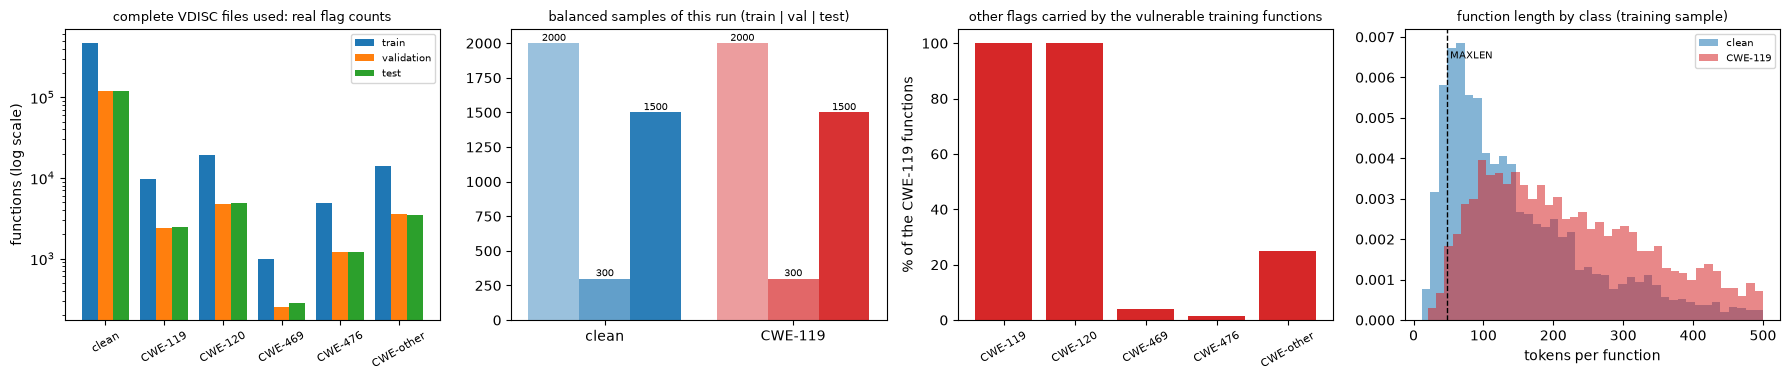

In [7]:
print("VDISC columns used:", ["functionSource"] + CWE_COLS, "(the mirror also has an integer column `combine`, not used)")
print("sample stored (rows, columns):", pool.shape, "| columns:", pool.columns.tolist())
print("original label values: each flag is a boolean (True / False). Complete files:")
tab = pd.DataFrame(counts).T; tab.index.name = "file"; print(tab.to_string())
print("\nshare of CWE-119 flagged functions: " + ", ".join(f"{k} {v['CWE-119']/v['n']*100:.2f}%" for k, v in counts.items()))
print("\nthis run (after duplicate removal): functions per class")
print(pd.DataFrame({p: {"vulnerable (CWE-119)": int(Y[p].sum()), "clean (no flag)": int((1 - Y[p]).sum())} for p in Y}).T.to_string())

ex = D["train"][D["train"].y == 1].iloc[0]
print("\none real CWE-119 function of the training sample (flags:", [c for c in CWE_COLS if ex[c]], ")"); print(ex.src[:500] + (" ..." if len(ex.src) > 500 else ""))
print("its first 25 tokens :", ex.toks[:25]); print("their vocabulary ids:", ex.ids[:25].tolist(), "-> basic input:", np.round(ex.ids[:8] / V, 4).tolist(), "...")

fig, ax = plt.subplots(1, 4, figsize=(18, 3.9))
names = ["clean"] + CWE_COLS; w = 0.27
for k, (sp_, c_) in enumerate((("train", "tab:blue"), ("validation", "tab:orange"), ("test", "tab:green"))):
    ax[0].bar(np.arange(len(names)) + (k - 1) * w, [counts[sp_][n] for n in ["clean"] + CWE_COLS], w, label=sp_, color=c_)
ax[0].set_yscale("log"); ax[0].set_xticks(range(len(names))); ax[0].set_xticklabels(names, rotation=30, fontsize=8); ax[0].set_ylabel("functions (log scale)")
ax[0].set_title("complete VDISC files used: real flag counts", fontsize=9); ax[0].legend(fontsize=7)
for k, p in enumerate(("train", "val", "test")):
    n_ = [int((1 - Y[p]).sum()), int(Y[p].sum())]; bars = ax[1].bar(np.arange(2) + (k - 1) * w, n_, w, color=["tab:blue", "tab:red"], alpha=0.45 + 0.25 * k)
    for b_, v_ in zip(bars, n_): ax[1].text(b_.get_x() + b_.get_width() / 2, v_, str(v_), ha="center", va="bottom", fontsize=7)
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["clean", "CWE-119"]); ax[1].set_title("balanced samples of this run (train | val | test)", fontsize=9)
pos_tr = D["train"][D["train"].y == 1]; ax[2].bar(CWE_COLS, [pos_tr[c].mean() * 100 for c in CWE_COLS], color="tab:red")
ax[2].set_ylabel("% of the CWE-119 functions"); ax[2].set_xticklabels(CWE_COLS, rotation=30, fontsize=8); ax[2].set_title("other flags carried by the vulnerable training functions", fontsize=9)
for p_, c_, l_ in ((0, "tab:blue", "clean"), (1, "tab:red", "CWE-119")):
    ax[3].hist(np.minimum(D["train"][D["train"].y == p_].ids.map(len), 500), bins=40, alpha=.55, color=c_, label=l_, density=True)
ax[3].axvline(MAXLEN, color="k", ls="--", lw=1); ax[3].text(MAXLEN, ax[3].get_ylim()[1] * .9, " MAXLEN", fontsize=7); ax[3].set_xlabel("tokens per function"); ax[3].set_title("function length by class (training sample)", fontsize=9); ax[3].legend(fontsize=7)
plt.tight_layout(); plt.show()

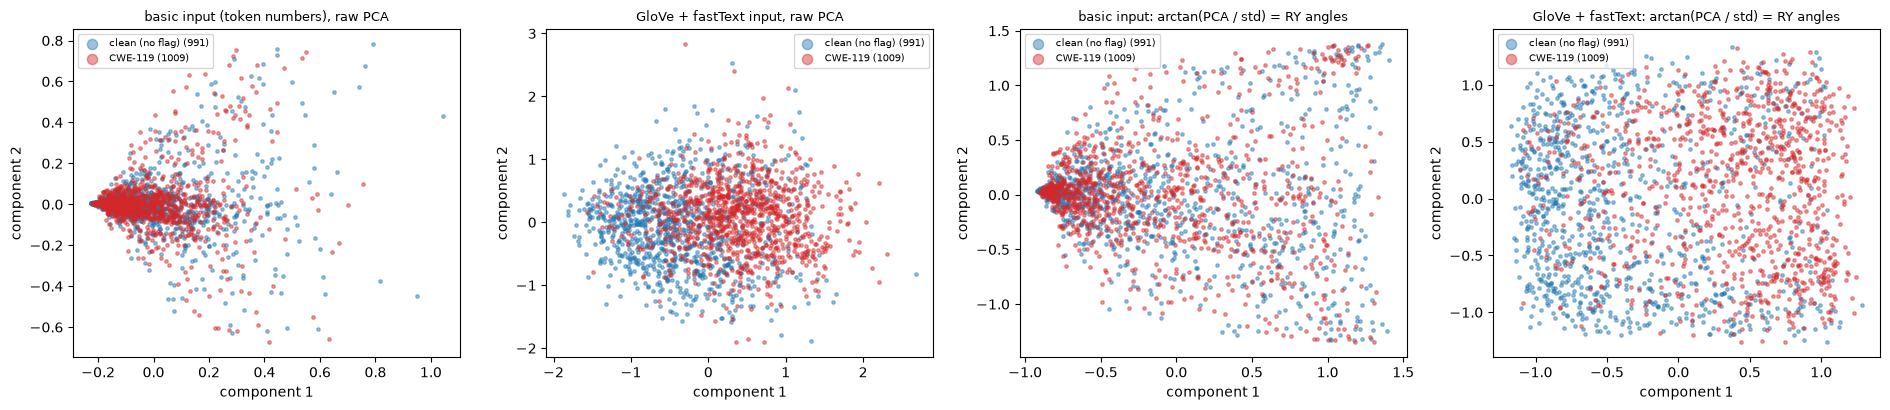

explained variance of the two PCA components (training split): basic 0.046, 0.037 | GloVe+fastText 0.248, 0.151


natural-mix sample (real class mix of the train file): {'clean': 11305, 'CWE-120': 154, 'several flags': 208, 'CWE-476': 111, 'CWE-other': 222}


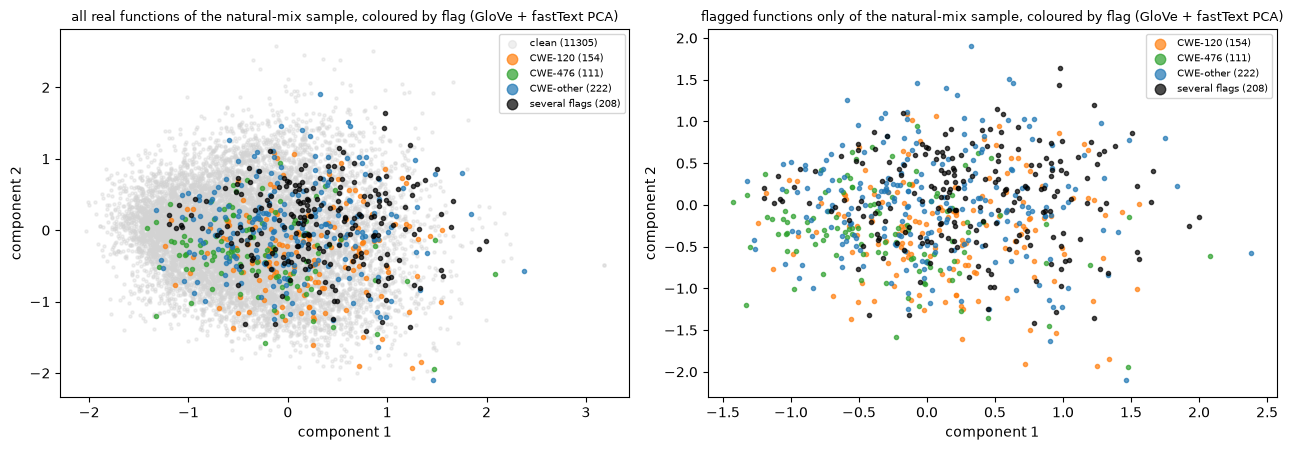

In [8]:
# ---- 2-D projections of real functions, coloured by the true label. PCA is fitted on the training split only. ----
def mean_vec(X, ids): m = (ids > 0)[:, :, None]; return (X * m).sum(1) / np.maximum(m.sum(1), 1)          # average word vector over the real (non-padding) tokens
Xb_tr = CLS_IN["basic"]["train"][:, :, 0]; Xe_tr = mean_vec(REPR["GloVe+fastText"]["train"], IDS["train"])
pca_b = PCA(2, random_state=SEED).fit(Xb_tr); pca_e = PCA(2, random_state=SEED).fit(Xe_tr)
col = {0: "tab:blue", 1: "tab:red"}; lab = {0: "clean (no flag)", 1: "CWE-119"}
sub = np.random.default_rng(SEED).choice(len(Y["train"]), size=min(2000, len(Y["train"])), replace=False)
fig, ax = plt.subplots(1, 4, figsize=(19, 4.2))
for a, (P, ttl) in zip(ax, ((pca_b.transform(Xb_tr[sub]), "basic input (token numbers), raw PCA"), (pca_e.transform(Xe_tr[sub]), "GloVe + fastText input, raw PCA"),
                            (np.arctan(pca_b.transform(Xb_tr[sub]) / pca_b.transform(Xb_tr).std(0)), "basic input: arctan(PCA / std) = RY angles"),
                            (np.arctan(pca_e.transform(Xe_tr[sub]) / pca_e.transform(Xe_tr).std(0)), "GloVe + fastText: arctan(PCA / std) = RY angles"))):
    for c_ in (0, 1):
        m_ = Y["train"][sub] == c_; a.scatter(P[m_, 0], P[m_, 1], s=6, alpha=.45, c=col[c_], label=f"{lab[c_]} ({m_.sum()})")
    a.set_title(ttl, fontsize=9); a.set_xlabel("component 1"); a.set_ylabel("component 2"); a.legend(markerscale=3, fontsize=7)
plt.tight_layout(); plt.show()
print("explained variance of the two PCA components (training split): basic %.3f, %.3f | GloVe+fastText %.3f, %.3f" % (*pca_b.explained_variance_ratio_, *pca_e.explained_variance_ratio_))

# ---- multiclass view: a natural-mix sample of real functions (all five flags), same PCA (fitted on the training split) ----
nat = D["corpus"]
def flag_class(r):
    fl = [c for c in CWE_COLS if r[c]]; return "clean" if not fl else (fl[0] if len(fl) == 1 else "several flags")
nat_cls = nat.apply(flag_class, axis=1).to_numpy(); ids_nat = pad(nat.ids); Xn = mean_vec(emb_repr(ids_nat), ids_nat); Pn = pca_e.transform(Xn)
palette = {"clean": "lightgrey", "CWE-119": "tab:red", "CWE-120": "tab:orange", "CWE-469": "tab:purple", "CWE-476": "tab:green", "CWE-other": "tab:blue", "several flags": "black"}
print("natural-mix sample (real class mix of the train file):", dict(collections.Counter(nat_cls)))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for k, (a, sel) in enumerate(zip(ax, (list(palette), [c for c in palette if c != "clean"]))):
    for c_ in sel:
        m_ = nat_cls == c_
        if m_.sum(): a.scatter(Pn[m_, 0], Pn[m_, 1], s=5 if c_ == "clean" else 9, alpha=.35 if c_ == "clean" else .7, c=palette[c_], label=f"{c_} ({m_.sum()})")
    a.set_title(("all real functions" if k == 0 else "flagged functions only") + " of the natural-mix sample, coloured by flag (GloVe + fastText PCA)", fontsize=9)
    a.set_xlabel("component 1"); a.set_ylabel("component 2"); a.legend(markerscale=2.5, fontsize=7)
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The QLSTM contains **six variational quantum circuits** (VQC1-VQC6) of the *same architecture* with their own trainable angles (paper Section 4: "6 VQCs, each with 4 qubits and 2 depths in each variational layer"). VQC1-VQC4 are the forget, input, candidate and output gates, VQC5 produces the hidden state and VQC6 the output (paper Section 3.3). The drawing is made from the real PennyLane QNode (`default.qubit`) that the notebook uses as reference simulator. Its three parts, in the order they act (paper Fig. 5: data encoding, variational layer, quantum measurement):

1. **Data encoding** (`U(x)`, paper Fig. 4): a **Hadamard** on every qubit, then qubit *i* receives one classical number *x_i* through `RY(arctan x_i)` followed by `RZ(arctan x_i^2)`. *Assumption (paper silent on the gates):* this is the encoding of Chen, Yoo and Fang's QLSTM, which the paper cites as the model it follows.
2. **Variational layers** (`Q_DEPTH = 2`, the "2 depths"): each layer is a **CNOT ladder** (entanglement: pairs (0,1), (2,3), then (1,2)) followed by a trainable **`Rot(phi, theta, omega)`** on every qubit: 12 trainable angles per layer, 24 per circuit.
3. **Measurement**: the expectation value of Pauli-Z on every qubit, one number per qubit, which the classical layers around the circuit turn into the gate value.

*Assumptions (paper silent):* the exact gate sequence, the entangler, how many classical numbers enter a circuit (a linear layer squeezes `[h, x]` to 4 angles, as in Chen et al.), and how the 4 outputs are mapped back to the hidden size. All six circuits have the same architecture, so **one drawing** shows them all; the equivalence check after it covers all six inside the whole QLSTM cell.

Matplotlib is building the font cache; this may take a moment.


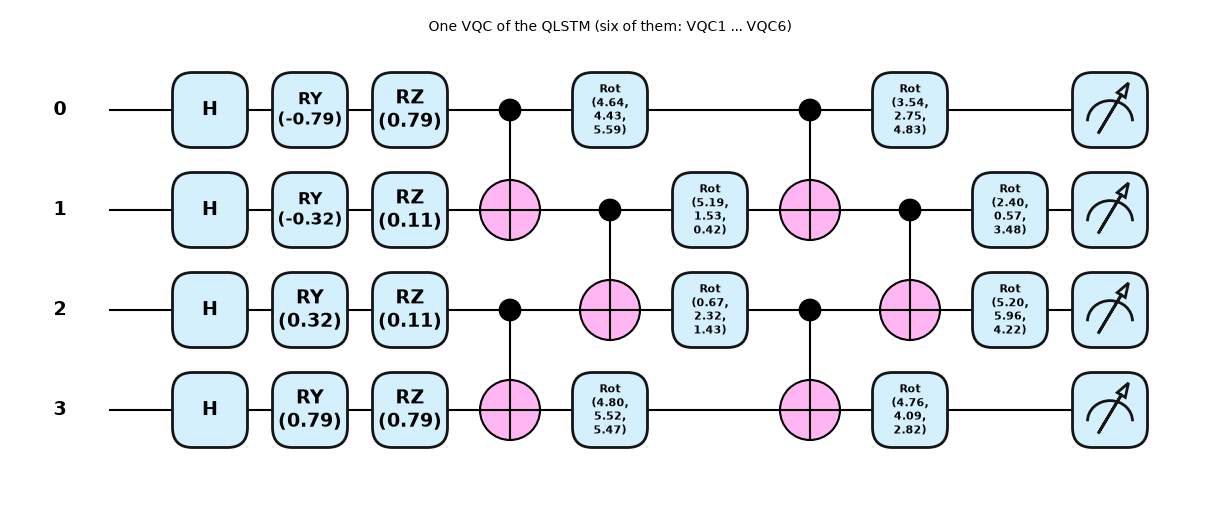

qubits: 4 | circuit depth: 9 | gates: 26 | gate types: {'Hadamard': 4, 'RY': 4, 'RZ': 4, 'CNOT': 6, 'Rot': 8}
trainable parameters per VQC: 2 layers x 4 qubits x 3 angles = 24
trainable circuit parameters in the whole QLSTM cell (6 VQCs): 144


In [9]:
def make_pl_vqc(n=N_QUBITS, L=Q_DEPTH):
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def vqc(inputs, weights):
        for i in range(n): qml.Hadamard(wires=i)                                            # data encoding U(x): H, RY(arctan x), RZ(arctan x^2)
        for i in range(n): qml.RY(torch.arctan(inputs[..., i]), wires=i)                    # CHOICE: Chen et al. QLSTM encoding
        for i in range(n): qml.RZ(torch.arctan(inputs[..., i] ** 2), wires=i)
        for l in range(L):                                                                  # paper: 2 depths in each variational layer
            for i in range(0, n - 1, 2): qml.CNOT(wires=[i, i + 1])                         # CHOICE: CNOT ladder + Rot layer
            for i in range(1, n - 1, 2): qml.CNOT(wires=[i, i + 1])
            for i in range(n): qml.Rot(weights[l, i, 0], weights[l, i, 1], weights[l, i, 2], wires=i)
        return [qml.expval(qml.PauliZ(i)) for i in range(n)]                                # <Z_i>, one number per qubit
    return vqc

PL_VQC = make_pl_vqc()
x_demo = torch.linspace(-1.0, 1.0, N_QUBITS); w_demo = torch.rand(Q_DEPTH, N_QUBITS, 3) * 2 * math.pi
fig, ax = qml.draw_mpl(PL_VQC, decimals=2, style="pennylane")(x_demo, w_demo)
fig.suptitle("One VQC of the QLSTM (six of them: VQC1 ... VQC6)", fontsize=10); plt.show()

sp = qml.specs(PL_VQC)(x_demo, w_demo)
try:
    res = sp["resources"]; depth, n_gates, gate_types = res.depth, res.num_gates, dict(res.gate_types)
except Exception:
    depth, n_gates, gate_types = sp.get("depth"), sp.get("num_operations"), sp.get("gate_types")
print(f"qubits: {N_QUBITS} | circuit depth: {depth} | gates: {n_gates} | gate types: {gate_types}")
print(f"trainable parameters per VQC: {Q_DEPTH} layers x {N_QUBITS} qubits x 3 angles = {Q_DEPTH * N_QUBITS * 3}")
print(f"trainable circuit parameters in the whole QLSTM cell ({N_VQC} VQCs): {N_VQC * Q_DEPTH * N_QUBITS * 3}")

### A fast twin of the circuit, proved equal to PennyLane

Training needs one circuit evaluation per VQC, per time step (one per token!) and per batch, with gradients, thousands of times. PennyLane's `default.qubit` is correct but slow in this setting, so the training loop uses a **PyTorch twin**: the same circuit written as an exact state-vector computation (the encoding gives a product state; each layer is one 2^n x 2^n unitary built from the `Rot` angles; Pauli-Z expectations are read from the probabilities). The next cell proves that twin and QNode are the same function, for **values and gradients**, in float64, for several depths.

In [10]:
_tab = {}
def tables(n):
    if n not in _tab:
        idx = np.arange(2 ** n)
        bits = (idx[:, None] >> (n - 1 - np.arange(n))[None, :]) & 1                      # wire 0 = most significant bit (PennyLane order)
        zsign = torch.tensor(1.0 - 2.0 * bits, dtype=torch.float64)
        pairs = [(i, i + 1) for i in range(0, n - 1, 2)] + [(i, i + 1) for i in range(1, n - 1, 2)]
        perm = idx.copy()
        for c_, t_ in pairs:
            fl = idx ^ (((idx >> (n - 1 - c_)) & 1) << (n - 1 - t_)); perm = perm[fl]       # the CNOT ladder as a basis permutation
        _tab[n] = (zsign, torch.tensor(perm, dtype=torch.long))
    return _tab[n]

def layer_unitaries(weights, cdt):
    # weights (G, L, n, 3) -> list of L unitaries (G, 2^n, 2^n): tensor product of Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi) on every wire
    G, L, n, _ = weights.shape; Ws = []
    for l in range(L):
        phi, th, om = weights[:, l, :, 0], weights[:, l, :, 1], weights[:, l, :, 2]
        c_, s_ = torch.cos(th / 2).to(cdt), torch.sin(th / 2).to(cdt); a_, b_ = ((phi + om) / 2).to(cdt), ((phi - om) / 2).to(cdt)
        M = torch.stack([torch.stack([torch.exp(-1j * a_) * c_, -torch.exp(1j * b_) * s_], -1),
                         torch.stack([torch.exp(-1j * b_) * s_, torch.exp(1j * a_) * c_], -1)], -2)       # (G, n, 2, 2)
        W = M[:, 0]
        for k in range(1, n):
            d = W.shape[-1]; W = torch.einsum('gab,gcd->gacbd', W, M[:, k]).reshape(G, 2 * d, 2 * d)
        Ws.append(W)
    return Ws

def expect_twin(inputs, Ws, n):
    # inputs (G, B, n) -> (G, B, n): <Z_i> of G independent circuits on B inputs each (float32 or float64 follows the input dtype)
    G, B, _ = inputs.shape; dt = inputs.dtype; cdt = torch.complex64 if dt == torch.float32 else torch.complex128
    zsign, perm = tables(n); zsign = zsign.to(dt)
    a = torch.arctan(inputs) / 2; b = torch.arctan(inputs ** 2) / 2                       # half angles of RY(arctan x), RZ(arctan x^2)
    c_, s_ = torch.cos(a), torch.sin(a); r2 = 1 / math.sqrt(2)
    q = torch.stack([((c_ - s_) * r2).to(cdt) * torch.exp(-1j * b.to(cdt)), ((s_ + c_) * r2).to(cdt) * torch.exp(1j * b.to(cdt))], -1)   # RZ RY H|0> per wire
    psi = q[:, :, 0, :]
    for k in range(1, n): psi = (psi.unsqueeze(-1) * q[:, :, k, :].unsqueeze(-2)).reshape(G, B, -1)                                    # product state
    for W in Ws:
        psi = psi[..., perm]                                                              # CNOT ladder
        psi = torch.bmm(psi, W.transpose(1, 2))                                           # Rot layer
    return (psi.real ** 2 + psi.imag ** 2) @ zsign

def expect_pl(inputs, weights, vqc=None):
    # same quantity from the PennyLane QNode (reference); inputs (G, B, n) are broadcast over B
    vqc = vqc or PL_VQC
    return torch.stack([torch.stack(vqc(inputs[g], weights[g]), -1) for g in range(inputs.shape[0])])

# ---- proof: twin == PennyLane, values and gradients (float64), several depths ----
torch.manual_seed(SEED); G_, B_ = 3, 5
for L_ in (1, 2, 4):
    vq = make_pl_vqc(N_QUBITS, L_)
    xs = (torch.randn(G_, B_, N_QUBITS, dtype=torch.float64) * 2).requires_grad_()
    ws = (torch.rand(G_, L_, N_QUBITS, 3, dtype=torch.float64) * 2 * math.pi).requires_grad_()
    ref = expect_pl(xs, ws, vq); tw = expect_twin(xs, layer_unitaries(ws, torch.complex128), N_QUBITS)
    gr = torch.autograd.grad((ref * torch.arange(1, N_QUBITS + 1)).sum(), (xs, ws)); gt = torch.autograd.grad((tw * torch.arange(1, N_QUBITS + 1)).sum(), (xs, ws))
    d_val = float((ref - tw).abs().max()); d_gx = float((gr[0] - gt[0]).abs().max()); d_gw = float((gr[1] - gt[1]).abs().max())
    print(f"depth {L_}: max |value difference| = {d_val:.2e} | max |gradient difference| inputs {d_gx:.2e}, weights {d_gw:.2e}")
    assert d_val < 1e-10 and d_gx < 1e-10 and d_gw < 1e-10, "twin and PennyLane disagree"
print("OK: the PyTorch twin is the same circuit as the drawn PennyLane QNode.")

depth 1: max |value difference| = 5.55e-16 | max |gradient difference| inputs 2.22e-15, weights 8.88e-15


depth 2: max |value difference| = 1.11e-15 | max |gradient difference| inputs 1.78e-15, weights 9.77e-15


depth 4: max |value difference| = 7.77e-16 | max |gradient difference| inputs 4.44e-15, weights 5.33e-15
OK: the PyTorch twin is the same circuit as the drawn PennyLane QNode.


## 4. The QLSTM and the classical LSTM

**Classical LSTM cell (reminder).** The network reads the tokens of a function one after the other. At each step it receives the current token vector `x_t` and the previous hidden state `h_(t-1)`. Three gates, each a small neural network with a sigmoid, decide what to *forget* from the memory `c`, what new information to *input* and what to *output*; a fourth network with a tanh proposes the new content: `c_t = f_t * c_(t-1) + i_t * c'_t`, and the output is `o_t * tanh(c_t)`. After the last token, a final layer turns the state into one number, the score "vulnerable".

**QLSTM cell (paper Section 3.3).** `v_t = [h_(t-1), x_t]` is squeezed by one classical linear layer to 4 numbers (one per qubit); VQC1 ... VQC4 turn them into 4 expectation values each; a classical linear layer per gate maps these back to the hidden size and the sigmoid / tanh of the equations is applied (`f_t`, `i_t`, `C'_t`, `o_t`). Then `u_t = o_t * tanh(c_t)` goes through VQC5 (and a linear layer and a sigmoid) to give `h_t`, and, after the last token, through VQC6 to give the output `y`. The paper says "2 parameters for scaling in the final step": the score is `a * mean(y) + b` with the two trainable numbers `a` and `b`.

**Matched classical networks.** (1) The paper's LSTM: 50 hidden units, one sigmoid output. (2) An LSTM whose number of trainable parameters is as close as possible to the QLSTM's, so that any difference cannot be blamed on model size. Both are trained with exactly the same optimiser, learning rate, batch size, epochs and training functions as the QLSTM.

In [11]:
class QLSTM(nn.Module):
    # QLSTM of the paper (Section 3.3). backend="twin": fast state-vector twin; backend="pennylane": the QNode (reference, slow).
    def __init__(self, g_in, hidden, n_qubits, depth, backend="twin", scale_init=3.0):
        super().__init__()
        self.H, self.n, self.backend = hidden, n_qubits, backend
        self.lin_in = nn.Linear(g_in + hidden, n_qubits)                       # v_t = [h, x] -> n angles for VQC1..VQC4 (CHOICE, as Chen et al.)
        self.w_out = nn.Parameter(torch.randn(4, n_qubits, hidden) / math.sqrt(n_qubits)); self.b_out = nn.Parameter(torch.zeros(4, 1, hidden))
        self.lin_h_in, self.lin_h_out = nn.Linear(hidden, n_qubits), nn.Linear(n_qubits, hidden)      # around VQC5 (hidden state)
        self.lin_y_in = nn.Linear(hidden, n_qubits)                            # in front of VQC6 (output)
        self.vqc_w = nn.Parameter(torch.rand(N_VQC, depth, n_qubits, 3) * 2 * math.pi)   # six circuits; CHOICE: U(0, 2pi) initial angles
        self.scale = nn.Parameter(torch.tensor([scale_init, 0.0]))             # paper: "2 parameters for scaling in the final step": score = a * mean(y) + b

    def circ(self, ang, Ws, lo, hi):
        if self.backend == "twin": return expect_twin(ang, [W[lo:hi] for W in Ws], self.n)
        return expect_pl(ang, self.vqc_w[lo:hi])

    def forward(self, x):                                                      # x: (B, T, g_in)
        B, T, _ = x.shape; h = c = torch.zeros(B, self.H, dtype=x.dtype)
        Ws = layer_unitaries(self.vqc_w, torch.complex64 if x.dtype == torch.float32 else torch.complex128) if self.backend == "twin" else None
        for t in range(T):
            ang = self.lin_in(torch.cat([h, x[:, t]], 1)).unsqueeze(0).expand(4, -1, -1)              # (4, B, n)
            o = torch.einsum('gbn,gnh->gbh', self.circ(ang, Ws, 0, 4), self.w_out) + self.b_out         # VQC1..VQC4 -> (4, B, H)
            f_, i_, g_, o_ = torch.sigmoid(o[0]), torch.sigmoid(o[1]), torch.tanh(o[2]), torch.sigmoid(o[3])   # f_t, i_t, C'_t, o_t
            c = f_ * c + i_ * g_                                                                        # c_t = f_t c_(t-1) + i_t C'_t
            u = o_ * torch.tanh(c)
            h = torch.sigmoid(self.lin_h_out(self.circ(self.lin_h_in(u).unsqueeze(0), Ws, 4, 5)[0]))   # h_t = sigmoid(VQC5(o_t tanh(c_t)))
        y = self.circ(self.lin_y_in(u).unsqueeze(0), Ws, 5, 6)[0]                                       # y_t = VQC6(o_t tanh(c_t)), last step only
        return self.scale[0] * y.mean(-1) + self.scale[1]

class TorchLSTM(nn.Module):
    # classical LSTM: one recurrent layer + one output (a logit; the sigmoid sits in the loss)
    def __init__(self, g_in, hidden):
        super().__init__(); self.rnn = nn.LSTM(g_in, hidden, batch_first=True); self.head = nn.Linear(hidden, 1)
    def forward(self, x): return self.head(self.rnn(x)[0][:, -1]).squeeze(-1)

class EmbWrap(nn.Module):
    # "basic" input: token numbers -> trainable embedding layer (random start, learned from the labels, like the Keras Embedding layer) -> recurrent core
    def __init__(self, core, vocab, dim):
        super().__init__(); self.emb = nn.Embedding(vocab, dim, padding_idx=0); self.core = core
    def forward(self, x): return self.core(self.emb(x))

n_par = lambda m: sum(p.numel() for p in m.parameters())
def make_net(kind, rep, hidden):
    # CHOICE: both representations enter the recurrent core as D_EMB numbers per token (basic: trainable embedding of that width; GloVe+fastText: frozen vectors)
    core = QLSTM(D_EMB, hidden, N_QUBITS, Q_DEPTH) if kind == "QLSTM" else TorchLSTM(D_EMB, hidden)
    return EmbWrap(core, V, D_EMB) if rep == "basic" else core
def matched_hidden(rep, target):
    # CHOICE: hidden size of the classical LSTM whose total parameter count is closest to the QLSTM's
    return min(range(1, 80), key=lambda h: abs(n_par(make_net("LSTM", rep, h)) - target))
PARAMS = {}
for rep in ("basic", "GloVe+fastText"):
    q = n_par(make_net("QLSTM", rep, Q_HIDDEN)); hm = matched_hidden(rep, q)
    PARAMS[rep] = dict(qlstm=q, circuit=N_VQC * Q_DEPTH * N_QUBITS * 3, lstm50=n_par(make_net("LSTM", rep, LSTM_UNITS)), hm=hm, lstm_m=n_par(make_net("LSTM", rep, hm)),
                       emb=(V * D_EMB if rep == "basic" else 0))
    print(f"{rep:15s} | QLSTM (hidden {Q_HIDDEN}): {q:,} trainable parameters (circuit angles {PARAMS[rep]['circuit']}, trainable embedding layer {PARAMS[rep]['emb']:,}) | "
          f"LSTM-50: {PARAMS[rep]['lstm50']:,} | size-matched LSTM (hidden {hm}): {PARAMS[rep]['lstm_m']:,}")
print("paper: LSTM 123,301 parameters, QLSTM 122,876. Most of them sit in a layer the paper does not describe; a trainable embedding of a few thousand tokens has this size.")

# ---- full-cell check: the QLSTM with the PennyLane backend gives the same score and gradients as the twin backend (float64) ----
set_seed(SEED)
m_tw = QLSTM(D_EMB, Q_HIDDEN, N_QUBITS, Q_DEPTH, "twin").double(); m_pl = QLSTM(D_EMB, Q_HIDDEN, N_QUBITS, Q_DEPTH, "pennylane").double()
m_pl.load_state_dict(m_tw.state_dict())
xb = torch.tensor(REPR["GloVe+fastText"]["train"][:3, -3:], dtype=torch.float64); yb = torch.tensor(Y["train"][:3], dtype=torch.float64)       # 3 real functions x their last 3 tokens
l_tw = F.binary_cross_entropy_with_logits(m_tw(xb), yb); l_pl = F.binary_cross_entropy_with_logits(m_pl(xb), yb)
l_tw.backward(); l_pl.backward()
d_l = abs(float(l_tw - l_pl)); d_g = max(float((p1.grad - p2.grad).abs().max()) for p1, p2 in zip(m_tw.parameters(), m_pl.parameters()))
print(f"full QLSTM, 3 functions x 3 tokens x (4+1) circuits + VQC6: |loss difference| = {d_l:.2e}, max |gradient difference| = {d_g:.2e}")
assert d_l < 1e-10 and d_g < 1e-9, "twin and PennyLane QLSTM disagree"
del m_tw, m_pl

basic           | QLSTM (hidden 8): 96,582 trainable parameters (circuit angles 144, trainable embedding layer 96,000) | LSTM-50: 112,851 | size-matched LSTM (hidden 4): 96,613


GloVe+fastText  | QLSTM (hidden 8): 582 trainable parameters (circuit angles 144, trainable embedding layer 0) | LSTM-50: 16,851 | size-matched LSTM (hidden 4): 613
paper: LSTM 123,301 parameters, QLSTM 122,876. Most of them sit in a layer the paper does not describe; a trainable embedding of a few thousand tokens has this size.


full QLSTM, 3 functions x 3 tokens x (4+1) circuits + VQC6: |loss difference| = 0.00e+00, max |gradient difference| = 8.33e-17


## 5. Metrics and training loop

The paper reports accuracy, precision, recall and F1 (Eqs. 8-11) with *vulnerable* as the positive class, plus the execution time. `train_torch` trains any of the PyTorch models with Adam on mini-batches and records after every epoch the training loss and the loss on the **validation** functions (never the test functions). Nothing is tuned on the test functions: the numbers reported are those of the **last epoch**. The models are trained on `TRAIN_PER_CLASS` vulnerable and as many clean training functions, re-drawn for every seed from the training sample, and evaluated on the whole balanced test sample. The execution time is training + prediction wall-clock on this CPU.

In [12]:
def metrics(y_true, y_pred):
    return dict(accuracy=accuracy_score(y_true, y_pred), precision=precision_score(y_true, y_pred, zero_division=0),
                recall=recall_score(y_true, y_pred, zero_division=0), f1=f1_score(y_true, y_pred, zero_division=0))

@torch.no_grad()
def predict_logits(model, X, bs=500):
    model.eval(); return torch.cat([model(torch.as_tensor(X[i:i + bs])) for i in range(0, len(X), bs)]).numpy()

def train_torch(model, Xa, ya, Xv, yv, Xb, epochs, batch, lr, seed, track=False, loss_fn=None, verbose=True):
    # Adam on mini-batches. Xa/ya: training functions, Xv/yv: validation functions (curves only), Xb: test functions. Returns history, test logits, seconds.
    set_seed(seed); opt = torch.optim.Adam(model.parameters(), lr=lr); loss_fn = loss_fn or F.binary_cross_entropy_with_logits
    g = torch.Generator().manual_seed(int(seed)); Xt, yt = torch.as_tensor(Xa), torch.as_tensor(ya, dtype=torch.float32)
    hist = dict(loss=[], acc=[], val_loss=[], val_acc=[]); t0 = time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xt), generator=g); tl = ta = 0.0
        for i in range(0, len(Xt), batch):
            ids = perm[i:i + batch]; opt.zero_grad(); lg = model(Xt[ids]); loss = loss_fn(lg, yt[ids])
            loss.backward(); opt.step(); tl += float(loss) * len(ids); ta += float(((lg > 0).float() == yt[ids]).sum())
        hist["loss"].append(tl / len(Xt)); hist["acc"].append(ta / len(Xt))
        if track and Xv is not None:
            lv = predict_logits(model, Xv); hist["val_loss"].append(float(loss_fn(torch.as_tensor(lv), torch.as_tensor(yv, dtype=torch.float32))))
            hist["val_acc"].append(float(((lv > 0) == yv).mean()))
            if verbose and (ep == 0 or (ep + 1) % 4 == 0 or ep + 1 == epochs):
                print(f"    epoch {ep+1:3d}/{epochs} | loss {hist['loss'][-1]:.4f} acc {hist['acc'][-1]:.4f} | val loss {hist['val_loss'][-1]:.4f} val acc {hist['val_acc'][-1]:.4f} | {time.time()-t0:.0f}s")
    lt = predict_logits(model, Xb) if Xb is not None else None
    return hist, lt, time.time() - t0

SEEDS = [SEED + 11 * k for k in range(N_SEEDS)]
def pick_train(seed):                         # CHOICE: TRAIN_PER_CLASS random functions of each class per seed (CPU simulation limit)
    r_ = np.random.default_rng(seed); pos, neg = np.flatnonzero(Y["train"] == 1), np.flatnonzero(Y["train"] == 0)
    return np.concatenate([r_.choice(pos, size=min(TRAIN_PER_CLASS, len(pos)), replace=False), r_.choice(neg, size=min(TRAIN_PER_CLASS, len(neg)), replace=False)])

# smoke test: cost of one QLSTM training step (CPU time, so that other jobs on the machine do not distort it)
set_seed(SEED); _m = QLSTM(D_EMB, Q_HIDDEN, N_QUBITS, Q_DEPTH); _opt = torch.optim.Adam(_m.parameters(), lr=Q_LR)
_X = torch.as_tensor(REPR["GloVe+fastText"]["train"][:Q_BATCH]); _y = torch.as_tensor(Y["train"][:Q_BATCH], dtype=torch.float32); t0 = time.process_time()
for _ in range(3): _opt.zero_grad(); F.binary_cross_entropy_with_logits(_m(_X), _y).backward(); _opt.step()
per_step = (time.process_time() - t0) / 3; n_tr = 2 * TRAIN_PER_CLASS
print(f"QLSTM step on {MAXLEN} tokens, batch {Q_BATCH}: {per_step*1000:.0f} ms CPU -> about {per_step * math.ceil(n_tr / Q_BATCH) * EPOCHS / 60:.1f} CPU-min per model for {EPOCHS} epochs on {n_tr} functions")
del _m, _opt

QLSTM step on 48 tokens, batch 64: 1115 ms CPU -> about 8.9 CPU-min per model for 15 epochs on 2000 functions


## 6. Tables 1 and 2: LSTM and QLSTM, basic and GloVe + fastText inputs

Every model sees exactly the same functions. The *basic* setting feeds one number per token (Table 1), the *GloVe + fastText* setting 32 numbers per token (Table 2). For each seed we train the paper's LSTM (50 hidden units), the size-matched LSTM and the QLSTM. The printouts show the progress of the QLSTM every four epochs.

In [13]:
RESULTS = {}      # (representation, model) -> list of dicts (one per seed)
HIST = {}         # (representation, model) -> list of histories
CM = {}           # (representation, model) -> confusion matrix of the first seed
yte = Y["test"]
def add_result(key, pred, seconds, params=None, hist=None, seed_idx=0):
    r = metrics(yte, pred); r["seconds"] = seconds; r["params"] = params
    RESULTS.setdefault(key, []).append(r)
    if hist is not None: HIST.setdefault(key, []).append(hist)
    if seed_idx == 0: CM[key] = confusion_matrix(yte, pred, labels=[0, 1])

NEURAL = ["LSTM (50 units, paper)", "LSTM (size-matched)", "QLSTM"]
def build(name, rep):
    if name.startswith("LSTM (50"): return make_net("LSTM", rep, LSTM_UNITS)
    if name.startswith("LSTM (size"): return make_net("LSTM", rep, PARAMS[rep]["hm"])
    return make_net("QLSTM", rep, Q_HIDDEN)

for rep in REPR:
    Xtr, Xva, Xte = REPR[rep]["train"], REPR[rep]["val"], REPR[rep]["test"]
    for k, s in enumerate(SEEDS):
        sb = pick_train(s)
        for name in NEURAL:
            set_seed(s); m = build(name, rep)
            if name == "QLSTM": print(f"=== {rep} | seed {s} | QLSTM ({N_QUBITS} qubits, depth {Q_DEPTH}, {N_VQC} VQCs, hidden {Q_HIDDEN}, {MAXLEN} tokens, {len(sb)} training functions) ===")
            hist, lt, sec = train_torch(m, Xtr[sb], Y["train"][sb], Xva, Y["val"], Xte, EPOCHS, Q_BATCH, Q_LR, s, track=True, verbose=(name == "QLSTM"))
            add_result((rep, name), (lt > 0).astype(int), sec, n_par(m), hist, k)
            r = RESULTS[(rep, name)][-1]
            print(f"  {rep:15s} {name:22s} seed {s}: acc {r['accuracy']*100:.2f} prec {r['precision']*100:.2f} recall {r['recall']*100:.2f} F1 {r['f1']*100:.2f} ({sec:.0f}s, {n_par(m)} parameters)")

  basic           LSTM (50 units, paper) seed 42: acc 82.10 prec 83.00 recall 80.73 F1 81.85 (69s, 112851 parameters)


  basic           LSTM (size-matched)    seed 42: acc 81.10 prec 79.81 recall 83.27 F1 81.50 (33s, 96613 parameters)
=== basic | seed 42 | QLSTM (4 qubits, depth 2, 6 VQCs, hidden 8, 48 tokens, 2000 training functions) ===


    epoch   1/15 | loss 0.6985 acc 0.5200 | val loss 0.6856 val acc 0.5350 | 94s


    epoch   4/15 | loss 0.4582 acc 0.8160 | val loss 0.6073 val acc 0.7050 | 545s


    epoch   8/15 | loss 0.2558 acc 0.9120 | val loss 0.5374 val acc 0.7833 | 737s


...

    epoch   4/15 | loss 0.5030 acc 0.7740 | val loss 0.5194 val acc 0.7467 | 74s


    epoch   8/15 | loss 0.4257 acc 0.8245 | val loss 0.4496 val acc 0.8100 | 149s


    epoch  12/15 | loss 0.4046 acc 0.8390 | val loss 0.4285 val acc 0.8217 | 225s


    epoch  15/15 | loss 0.4366 acc 0.8175 | val loss 0.4466 val acc 0.8250 | 267s


  GloVe+fastText  QLSTM                  seed 53: acc 82.37 prec 81.30 recall 84.07 F1 82.66 (268s, 582 parameters)


## 7. Classical machine-learning baselines on the identical inputs

A Random Forest and an RBF-kernel SVC receive **exactly the inputs of the networks** (the flattened `MAXLEN x numbers-per-token` array, same training functions, same test functions); the SVC's `C` is chosen on the validation functions. As a reference that does **not** use the same input we add a logistic regression on a TF-IDF bag of the *complete* token sequence (unigrams and bigrams): it ignores the order of the first `MAXLEN` tokens and looks at the whole function, so it shows how much information the truncated sequence leaves out.

In [14]:
def fit_eval_classic(name, rep, sb, seed):
    t0 = time.time(); A = CLS_IN[rep]["train"][sb].reshape(len(sb), -1); ya = Y["train"][sb]
    Bv = CLS_IN[rep]["val"].reshape(len(Y["val"]), -1); Bt = CLS_IN[rep]["test"].reshape(len(yte), -1)
    if name == "Random Forest":
        mdl = RandomForestClassifier(n_estimators=RF_TREES, random_state=seed, n_jobs=2).fit(A, ya)
    else:                                                                              # SVC (RBF): C chosen on the validation functions
        ii = np.random.default_rng(seed).choice(len(A), size=min(SVC_MAX, len(A)), replace=False)   # CHOICE: SVC subset
        cands = [SVC(kernel="rbf", C=C_, gamma="scale", random_state=seed).fit(A[ii], ya[ii]) for C_ in (1.0, 10.0)]
        mdl = max(cands, key=lambda m_: accuracy_score(Y["val"], m_.predict(Bv)))
    return mdl.predict(Bt), time.time() - t0

def fit_eval_tfidf(sb, seed):
    t0 = time.time(); txt = lambda part, idx=None: [" ".join(D[part].toks.iloc[i]) for i in (range(len(D[part])) if idx is None else idx)]
    tv = TfidfVectorizer(token_pattern=r"\S+", lowercase=False, ngram_range=(1, 2), min_df=2, max_features=30000, sublinear_tf=True)
    A = tv.fit_transform(txt("train", sb)); lr_ = LogisticRegression(C=10.0, max_iter=2000, random_state=seed).fit(A, Y["train"][sb])
    return lr_.predict(tv.transform(txt("test"))), time.time() - t0

for rep in REPR:
    for name in ("Random Forest", "SVC (RBF)"):
        for k, s in enumerate(SEEDS):
            pred, sec = fit_eval_classic(name, rep, pick_train(s), s); add_result((rep, name), pred, sec, None, None, k)
        r = RESULTS[(rep, name)]
        print(f"{rep:15s} {name:14s} acc {np.mean([x['accuracy'] for x in r])*100:.2f}  recall {np.mean([x['recall'] for x in r])*100:.2f}  F1 {np.mean([x['f1'] for x in r])*100:.2f}  ({len(r)} run(s), {np.mean([x['seconds'] for x in r]):.1f}s)")
for k, s in enumerate(SEEDS):
    pred, sec = fit_eval_tfidf(pick_train(s), s); add_result(("reference", "TF-IDF + logistic regression (whole function)"), pred, sec, None, None, k)
r = RESULTS[("reference", "TF-IDF + logistic regression (whole function)")]
print(f"reference: TF-IDF + logistic regression on the whole token sequence: acc {np.mean([x['accuracy'] for x in r])*100:.2f}  recall {np.mean([x['recall'] for x in r])*100:.2f}  F1 {np.mean([x['f1'] for x in r])*100:.2f}")

basic           Random Forest  acc 70.48  recall 71.00  F1 70.63  (2 run(s), 1.7s)


basic           SVC (RBF)      acc 51.58  recall 39.33  F1 44.83  (2 run(s), 1.6s)


GloVe+fastText  Random Forest  acc 81.40  recall 82.10  F1 81.53  (2 run(s), 7.9s)


GloVe+fastText  SVC (RBF)      acc 80.97  recall 80.53  F1 80.88  (2 run(s), 21.8s)


reference: TF-IDF + logistic regression on the whole token sequence: acc 86.57  recall 88.00  F1 86.76


## 8. The paper's sine-wave experiment (Fig. 7)

To show that the QLSTM "learns better", the paper trains both networks to reproduce a sine function for 30 epochs and compares the prediction after the first and the last epoch (blue = actual, red = predicted). The paper does not say how the sine data are fed; we use the usual setup of the QLSTM literature: the previous `SINE_STEPS = 4` values of `sin(x)` as a sequence, the next value as target, mean-squared-error loss, the first 70 % of the curve for training and the last 30 % as a test region the network has never seen. The QLSTM is the same model as above (4 qubits, depth 2, 6 VQCs, 2 scaling parameters, one number per step); the LSTM has the size-matched number of parameters. Both use Adam with the same learning rate.

LSTM (size-matched)  (442 parameters): test-region MSE after epoch 1 = 0.2119, after epoch 30 = 0.0005 | training MSE 0.4115 -> 0.0006 | 1s


QLSTM                (458 parameters): test-region MSE after epoch 1 = 0.4361, after epoch 30 = 0.0037 | training MSE 0.5100 -> 0.0044 | 11s


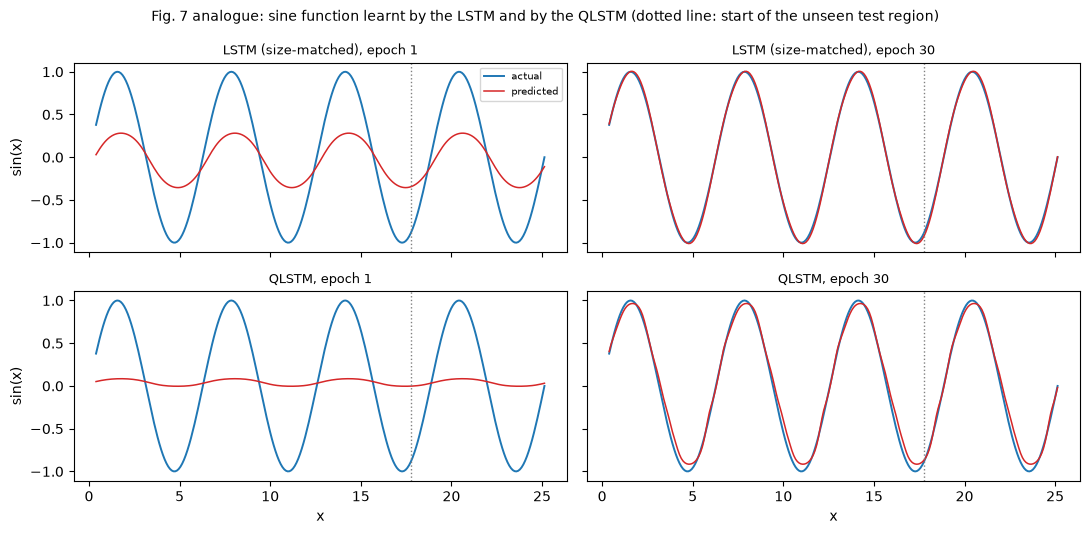

In [15]:
xs_ = np.linspace(0, 8 * np.pi, 260); sine = np.sin(xs_).astype(np.float32)          # CHOICE: four periods, 260 points
Xs = np.stack([sine[i:i + SINE_STEPS] for i in range(len(sine) - SINE_STEPS)])[:, :, None]; ys = sine[SINE_STEPS:]
n_trs = int(0.7 * len(Xs)); Xs_tr, ys_tr, Xs_te, ys_te = Xs[:n_trs], ys[:n_trs], Xs[n_trs:], ys[n_trs:]
HM_SINE = min(range(1, 80), key=lambda h: abs(n_par(TorchLSTM(1, h)) - n_par(QLSTM(1, Q_HIDDEN, N_QUBITS, Q_DEPTH))))      # CHOICE: LSTM with the QLSTM's parameter count
SINE = {}
for name, mk in (("LSTM (size-matched)", lambda: TorchLSTM(1, HM_SINE)), ("QLSTM", lambda: QLSTM(1, Q_HIDDEN, N_QUBITS, Q_DEPTH, scale_init=1.0))):
    set_seed(SEED); m = mk(); opt = torch.optim.Adam(m.parameters(), lr=Q_LR); g = torch.Generator().manual_seed(SEED)
    Xt_, yt_ = torch.as_tensor(Xs_tr), torch.as_tensor(ys_tr); snaps = {}; mse_tr, mse_te = [], []; t0 = time.time()
    for ep in range(SINE_EPOCHS):
        m.train(); perm = torch.randperm(len(Xt_), generator=g); tl = 0.0
        for i in range(0, len(Xt_), 16):
            ids = perm[i:i + 16]; opt.zero_grad(); loss = F.mse_loss(m(Xt_[ids]), yt_[ids]); loss.backward(); opt.step(); tl += float(loss) * len(ids)
        pr_all = predict_logits(m, Xs); mse_tr.append(tl / len(Xt_)); mse_te.append(float(((pr_all[n_trs:] - ys_te) ** 2).mean()))
        if ep in (0, SINE_EPOCHS - 1): snaps[ep + 1] = pr_all
    SINE[name] = dict(snaps=snaps, mse_tr=mse_tr, mse_te=mse_te, params=n_par(m), seconds=time.time() - t0)
    print(f"{name:20s} ({n_par(m)} parameters): test-region MSE after epoch 1 = {mse_te[0]:.4f}, after epoch {SINE_EPOCHS} = {mse_te[-1]:.4f} | training MSE {mse_tr[0]:.4f} -> {mse_tr[-1]:.4f} | {SINE[name]['seconds']:.0f}s")

fig, ax = plt.subplots(2, 2, figsize=(11, 5.4), sharex=True, sharey=True)
for r_, name in enumerate(SINE):
    for c_, ep in enumerate((1, SINE_EPOCHS)):
        a = ax[r_, c_]; a.plot(xs_[SINE_STEPS:], ys, color="tab:blue", lw=1.4, label="actual"); a.plot(xs_[SINE_STEPS:], SINE[name]["snaps"][ep], color="tab:red", lw=1.1, label="predicted")
        a.axvline(xs_[SINE_STEPS + n_trs], color="grey", ls=":", lw=1); a.set_title(f"{name}, epoch {ep}", fontsize=9)
        if r_ == 1: a.set_xlabel("x");
        if c_ == 0: a.set_ylabel("sin(x)")
ax[0, 0].legend(fontsize=7); fig.suptitle("Fig. 7 analogue: sine function learnt by the LSTM and by the QLSTM (dotted line: start of the unseen test region)", fontsize=10)
plt.tight_layout(); plt.show()

## 9. The paper's tables and figures, redrawn

*Learning curves.* Training loss, validation loss and validation accuracy of the QLSTM and of the two LSTMs against the epoch (mean over seeds, band = one standard deviation). *Tables 1 and 2 analogue.* Accuracy, precision, recall and F1 of every model (mean +- standard deviation over seeds, percent) and the execution time, the bar charts, the confusion matrices of the first seed (vulnerable = positive class) and the baselines.

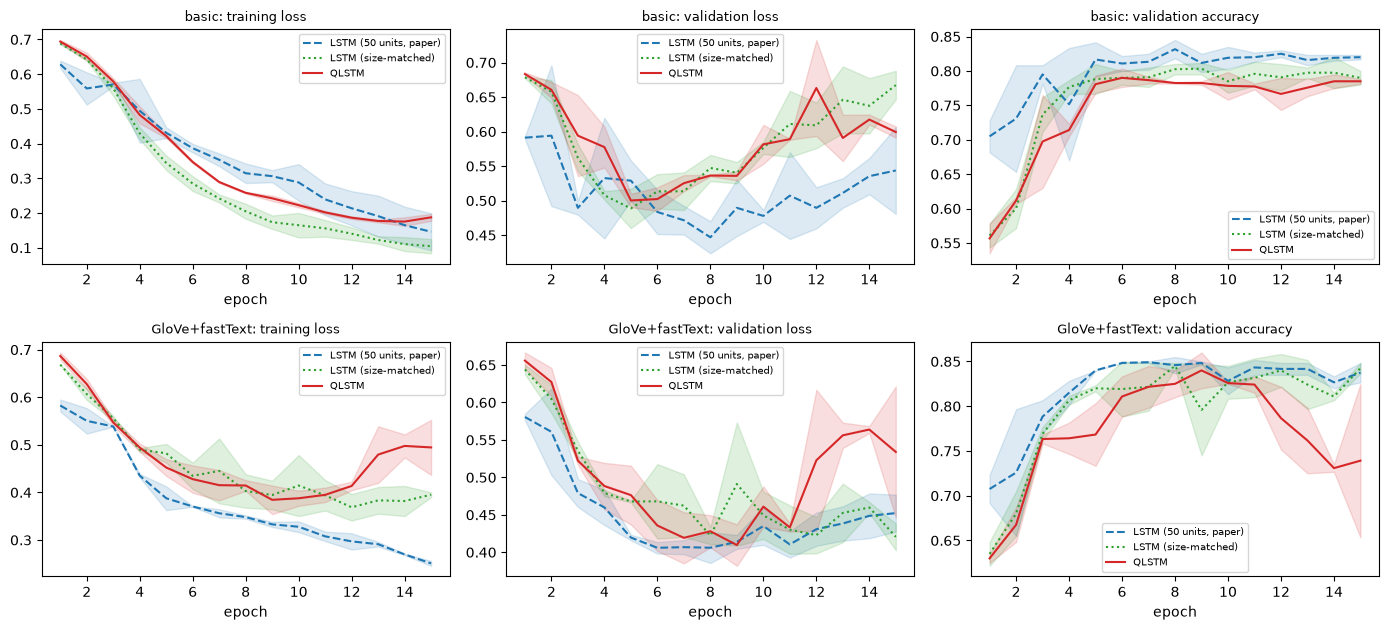

Table 1 analogue: basic input representation
representation                  model    accuracy %   precision %      recall %          f1 % train+predict s  params  runs
         basic LSTM (50 units, paper) 82.55 +- 0.45 85.08 +- 2.08 79.07 +- 1.67 81.92 +- 0.07              45  112851     2
         basic    LSTM (size-matched) 80.55 +- 0.55 80.03 +- 0.22 81.43 +- 1.83 80.71 +- 0.79              20   96613     2
         basic                  QLSTM 80.25 +- 0.32 78.37 +- 1.12 83.63 +- 1.23 80.90 +- 0.02             672   96582     2

Table 2 analogue: GloVe + fastText
representation                  model    accuracy %   precision %      recall %          f1 % train+predict s  params  runs
GloVe+fastText LSTM (50 units, paper) 84.87 +- 0.27 89.44 +- 0.48 79.07 +- 0.07 83.94 +- 0.25              15   16851     2
GloVe+fastText    LSTM (size-matched) 84.12 +- 0.25 86.79 +- 1.71 80.57 +- 1.57 83.53 +- 0.05               5     613     2
GloVe+fastText                  QLSTM 75.52 +- 6.85

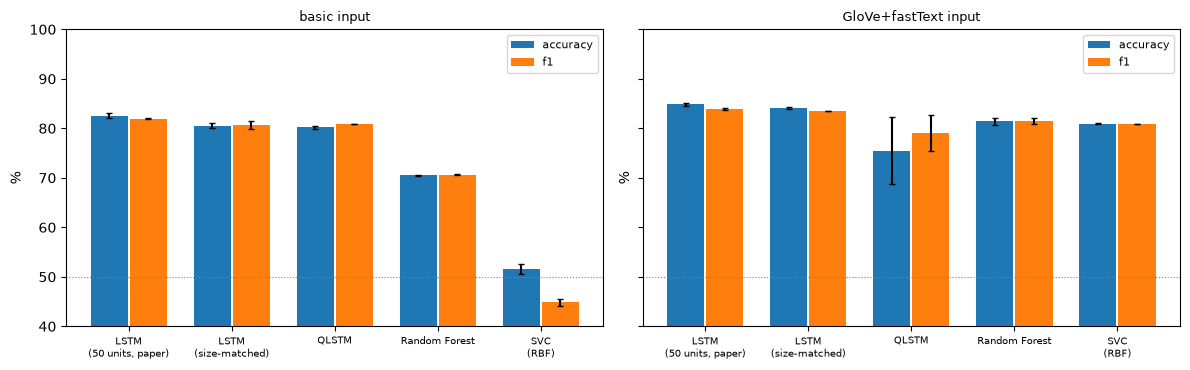

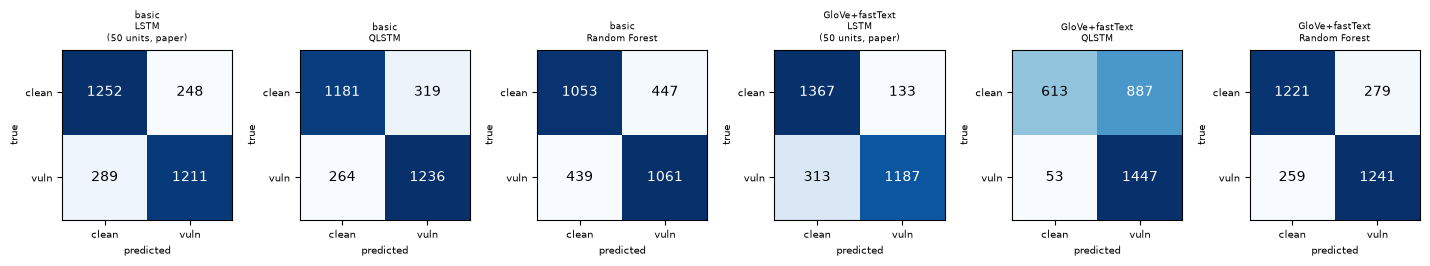

In [16]:
def band(ax, hs, key, label, color, ls="-"):
    A = np.array([h[key] for h in hs]); m, sd = A.mean(0), A.std(0); xs = np.arange(1, A.shape[1] + 1)
    ax.plot(xs, m, label=label, color=color, ls=ls); ax.fill_between(xs, m - sd, m + sd, color=color, alpha=.15)

fig, ax = plt.subplots(2, 3, figsize=(14, 6.4))
for r_, rep in enumerate(REPR):
    for name, c_, ls in (("LSTM (50 units, paper)", "tab:blue", "--"), ("LSTM (size-matched)", "tab:green", ":"), ("QLSTM", "tab:red", "-")):
        hs = HIST[(rep, name)]
        band(ax[r_, 0], hs, "loss", name, c_, ls); band(ax[r_, 1], hs, "val_loss", name, c_, ls); band(ax[r_, 2], hs, "val_acc", name, c_, ls)
    ax[r_, 0].set_title(f"{rep}: training loss", fontsize=9); ax[r_, 1].set_title(f"{rep}: validation loss", fontsize=9); ax[r_, 2].set_title(f"{rep}: validation accuracy", fontsize=9)
    for a in ax[r_]: a.set_xlabel("epoch"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

def tab_for(keys):
    rows = []
    for key in keys:
        rs_ = RESULTS[key]; d = {"representation": key[0], "model": key[1]}
        for m_ in ("accuracy", "precision", "recall", "f1"):
            v = np.array([r[m_] for r in rs_]) * 100; d[m_ + " %"] = f"{v.mean():.2f} +- {v.std():.2f}"
        d["train+predict s"] = f"{np.mean([r['seconds'] for r in rs_]):.0f}"; d["params"] = rs_[0]["params"] if rs_[0]["params"] else "-"; d["runs"] = len(rs_); rows.append(d)
    return pd.DataFrame(rows)
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 60)
print("Table 1 analogue: basic input representation");  print(tab_for([("basic", m) for m in NEURAL]).to_string(index=False))
print("\nTable 2 analogue: GloVe + fastText");           print(tab_for([("GloVe+fastText", m) for m in NEURAL]).to_string(index=False))
print("\nClassical baselines (same inputs; the last row uses the whole function):")
print(tab_for([(rep, m) for rep in REPR for m in ("Random Forest", "SVC (RBF)")] + [("reference", "TF-IDF + logistic regression (whole function)")]).to_string(index=False))

# bar charts: accuracy and F1 of the three networks and the two classical models, both representations
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True); allm = NEURAL + ["Random Forest", "SVC (RBF)"]
for a, rep in zip(ax, REPR):
    for j, m_ in enumerate(("accuracy", "f1")):
        vals = [100 * np.mean([r[m_] for r in RESULTS[(rep, nm)]]) for nm in allm]; sds = [100 * np.std([r[m_] for r in RESULTS[(rep, nm)]]) for nm in allm]
        a.bar(np.arange(len(allm)) + 0.38 * j - 0.19, vals, 0.36, yerr=sds, label=m_, capsize=2)
    a.set_xticks(range(len(allm))); a.set_xticklabels([n.replace(" (", "\n(") for n in allm], fontsize=7); a.set_title(rep + " input", fontsize=9); a.axhline(50, color="grey", lw=.8, ls=":"); a.set_ylim(40, 100); a.legend(fontsize=8); a.set_ylabel("%")
plt.tight_layout(); plt.show()

keys = [(rep, m) for rep in REPR for m in ("LSTM (50 units, paper)", "QLSTM", "Random Forest")]
fig, ax = plt.subplots(1, len(keys), figsize=(2.4 * len(keys), 2.9))
for a, key in zip(np.atleast_1d(ax), keys):
    cm = CM[key]; a.imshow(cm, cmap="Blues"); a.set_xticks([0, 1]); a.set_xticklabels(["clean", "vuln"], fontsize=7); a.set_yticks([0, 1]); a.set_yticklabels(["clean", "vuln"], fontsize=7)
    for i in range(2):
        for j in range(2): a.text(j, i, cm[i, j], ha="center", va="center", color="w" if cm[i, j] > cm.max() / 2 else "k")
    a.set_title(f"{key[0]}\n{key[1]}".replace(" (", "\n("), fontsize=6.5); a.set_xlabel("predicted", fontsize=7); a.set_ylabel("true", fontsize=7)
plt.tight_layout(); plt.show()

## 10. Side by side with the paper, claim by claim

Verdict rule (project brief): a metric is **reproduced** when our value lies within 2 percentage points of the paper's (the same 0.02 tolerance is used for accuracy, precision, recall and F1), otherwise **exceeded** (ours higher) or **not reached** (ours lower) with the gap; **cannot be checked** when the claim cannot be tested with the information and compute available. "Ours" is the mean over seeds at the last epoch. Ranking claims are checked on the means. The last block tests whether the paper's own tables are consistent with each other (on a balanced test set, accuracy and F1 follow from precision and recall).

In [17]:
def mean_of(key, m_): return 100 * float(np.mean([r[m_] for r in RESULTS[key]]))
def sec_of(key): return float(np.mean([r["seconds"] for r in RESULTS[key]]))
def verdict(ours, paper, tol=2.0):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else (f"exceeded (+{d:.1f})" if d > 0 else f"not reached ({d:.1f})")

# paper numbers: (accuracy, precision, recall, F1) in percent, and execution time in seconds
PAPER = {("basic", "LSTM (50 units, paper)"): ((90, 90, 90, 92), 40 * 60 + 2), ("basic", "QLSTM"): ((94, 99, 98, 99), 13 * 60 + 52),
         ("GloVe+fastText", "LSTM (50 units, paper)"): ((92, 93, 95, 97), 42 * 60 + 13), ("GloVe+fastText", "QLSTM"): ((95, 97, 98, 99), 19 * 60 + 11)}
TAB = {"basic": "Table 1", "GloVe+fastText": "Table 2"}; MET = ("accuracy", "precision", "recall", "f1")
rows = []
for (rep, nm), (vals, _) in PAPER.items():
    for m_, pv in zip(MET, vals):
        o = mean_of((rep, nm), m_); rows.append([f"{TAB[rep]}, {nm.split(' (')[0]}, {m_}", f"{pv}%", f"{o:.2f}%", verdict(o, pv)])
for rep in REPR:
    a = {nm: mean_of((rep, nm), "accuracy") for nm in NEURAL}
    rows.append([f"{TAB[rep]}: QLSTM beats the paper's LSTM (50 units) in accuracy", "yes", f"{a['QLSTM']:.2f}% vs {a['LSTM (50 units, paper)']:.2f}% (gap {a['QLSTM']-a['LSTM (50 units, paper)']:+.2f})", "reproduced" if a["QLSTM"] > a["LSTM (50 units, paper)"] else "not reached"])
    rows.append([f"{TAB[rep]}: QLSTM beats a size-matched LSTM in accuracy", "implied (same number of parameters)", f"{a['QLSTM']:.2f}% vs {a['LSTM (size-matched)']:.2f}% (gap {a['QLSTM']-a['LSTM (size-matched)']:+.2f})", "reproduced" if a["QLSTM"] > a["LSTM (size-matched)"] else "not reached"])
    ts_q, ts_l = sec_of((rep, "QLSTM")), sec_of((rep, "LSTM (50 units, paper)"))
    pq_, pl_ = PAPER[(rep, "QLSTM")][1], PAPER[(rep, "LSTM (50 units, paper)")][1]
    rows.append([f"{TAB[rep]}: QLSTM runs faster than the LSTM (paper: {pq_/60:.0f} vs {pl_/60:.0f} min, ratio {pl_/pq_:.1f}x)", f"{pl_/pq_:.1f}x faster", f"{ts_q:.0f}s vs {ts_l:.0f}s ({ts_q/ts_l:.1f}x {'slower' if ts_q > ts_l else 'faster'})", "reproduced" if ts_q < ts_l else "not reached (simulator is slower)"])
for nm in ("LSTM (50 units, paper)", "QLSTM"):
    ga = mean_of(("GloVe+fastText", nm), "accuracy") - mean_of(("basic", nm), "accuracy"); pg = PAPER[("GloVe+fastText", nm)][0][0] - PAPER[("basic", nm)][0][0]
    rows.append([f"GloVe + fastText improves the accuracy of the {nm.split(' (')[0]} (paper: {pg:+.0f} points)", f"{pg:+.0f}", f"{ga:+.2f}", ("direction reproduced" if ga > 0 else "direction not reached") + "; " + verdict(ga, pg)])
    tg = sec_of(("GloVe+fastText", nm)) / sec_of(("basic", nm)); pt = PAPER[("GloVe+fastText", nm)][1] / PAPER[("basic", nm)][1]
    rows.append([f"Embeddings make the {nm.split(' (')[0]} slower (paper: x{pt:.2f})", f"x{pt:.2f}", f"x{tg:.2f}", "reproduced" if tg > 1 else "not reached"])
q2 = ("GloVe+fastText", "QLSTM")
for lab_, pv, m_ in (("Headline (abstract): QLSTM accuracy 95%", 95, "accuracy"), ("Headline: QLSTM precision 97%", 97, "precision"), ("Headline: QLSTM recall 98%", 98, "recall"), ("Headline: QLSTM F1 99%", 99, "f1")):
    o = mean_of(q2, m_); rows.append([lab_, f"{pv}%", f"{o:.2f}%", verdict(o, pv)])
rf = max([(rep, "Random Forest") for rep in REPR] + [(rep, "SVC (RBF)") for rep in REPR], key=lambda k: mean_of(k, "accuracy"))
rows.append(["Added check: the QLSTM beats the best classical model on the same inputs", "implied", f"QLSTM {mean_of(q2,'accuracy'):.2f}% vs {rf[1]} ({rf[0]}) {mean_of(rf,'accuracy'):.2f}%", "reproduced" if mean_of(q2, "accuracy") > mean_of(rf, "accuracy") else "not reached"])
tf_ = ("reference", "TF-IDF + logistic regression (whole function)")
rows.append(["Added check: the QLSTM beats a bag-of-tokens model that sees the whole function", "implied", f"QLSTM {mean_of(q2,'accuracy'):.2f}% vs TF-IDF + LR {mean_of(tf_,'accuracy'):.2f}%", "reproduced" if mean_of(q2, "accuracy") > mean_of(tf_, "accuracy") else "not reached"])
sl, sq = SINE["LSTM (size-matched)"], SINE["QLSTM"]
rows.append(["Fig. 7: QLSTM learns the sine function better than the LSTM after epoch 1 (test-region MSE)", "yes (visual)", f"{sq['mse_te'][0]:.4f} vs {sl['mse_te'][0]:.4f}", "reproduced" if sq["mse_te"][0] < sl["mse_te"][0] else "not reached"])
rows.append([f"Fig. 7: QLSTM learns the sine function better than the LSTM after epoch {SINE_EPOCHS} (test-region MSE)", "yes (visual)", f"{sq['mse_te'][-1]:.4f} vs {sl['mse_te'][-1]:.4f}", "reproduced" if sq["mse_te"][-1] < sl["mse_te"][-1] else "not reached"])
rows.append(["Parameter counts: LSTM 123,301 and QLSTM 122,876 (equal size)", "123,301 / 122,876", f"{PARAMS['basic']['lstm50']:,} / {PARAMS['basic']['qlstm']:,} (basic); {PARAMS['GloVe+fastText']['lstm50']:,} / {PARAMS['GloVe+fastText']['qlstm']:,} (GloVe+fastText)", "cannot be checked (architecture of the rest of the network not described)"])
rows.append(["Execution times in minutes (40 / 14 / 42 / 19)", "minutes on an unknown machine", "seconds on this CPU with a state-vector simulator", "cannot be compared in absolute terms (see the ratio rows)"])
# internal consistency of the paper's own numbers (balanced classes assumed, as the paper states)
for (rep, nm), (vals, _) in PAPER.items():
    a_, p_, r_, f_ = (v / 100 for v in vals); f_imp = 2 * p_ * r_ / (p_ + r_); acc_imp = 0.5 * (r_ + 1 - r_ * (1 - p_) / p_)
    rows.append([f"Check, paper {TAB[rep]} {nm.split(' (')[0]}: F1 and accuracy implied by precision {vals[1]}% and recall {vals[2]}%", f"F1 {vals[3]}%, acc {vals[0]}%", f"F1 {f_imp*100:.1f}%, acc {acc_imp*100:.1f}% (balanced)", "consistent" if abs(f_imp - f_) < .015 and abs(acc_imp - a_) < .015 else "inconsistent"])
CMP = pd.DataFrame(rows, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 300)
print(CMP.to_string(index=False))
cat_ = CMP.verdict.map(lambda v: next((k for k in ("reproduced", "not reached", "exceeded", "cannot be", "direction", "inconsistent", "consistent") if v.startswith(k)), v))
print("\nverdict counts:", cat_.value_counts().to_dict())

                                                                                       claim                               paper                                           this notebook                                                                   verdict
                                                                     Table 1, LSTM, accuracy                                 90%                                                  82.55%                                                        not reached (-7.5)
                                                                    Table 1, LSTM, precision                                 90%                                                  85.08%                                                        not reached (-4.9)
                                                                       Table 1, LSTM, recall                                 90%                                                  79.07%                                       

## 11. Reading the paper critically

The headline is that the QLSTM with GloVe + fastText reaches 95 % accuracy (F1 99 %), beats the classical LSTM (92 %) and runs about twice as fast. What the paper itself shows, and what this notebook measured (the shipped run: 2 seeds, 2,000 training functions per run, 48 tokens per function, 15 epochs, 3,000 test functions; see the tables above), supports a more careful reading.

1. **None of the 16 table cells is reproduced.** Every accuracy, precision, recall and F1 of Tables 1 and 2 is 3.6 to 25 points higher in the paper than here (the closest, Table 2 LSTM precision, is 3.6 points away). Our budget is small (thousands of functions, the first 48 tokens, 15 epochs; the paper does not state its budget), so a gap is partly expected, but the *pattern* below does not support the paper's story either.
2. **The quantum model is not better.** With the basic input the QLSTM (80.3 +- 0.3 % accuracy) is 2.3 points below the paper's 50-unit LSTM (82.6 %) and equal within the seed noise to the size-matched LSTM (80.6 %); with GloVe + fastText the QLSTM averages 75.5 +- 6.9 % against 84.9 % and 84.1 % for the two LSTMs, because one of the two seeds ended unstable (68.7 % at the last epoch although its validation accuracy had been 84 % around epoch 8; the other seed reached 82.4 %). We report the last epoch, as the project rules require, rather than the best epoch. No setting shows the paper's 2 to 4 point advantage of the QLSTM.
3. **The execution-time claim is not reproduced and cannot be.** The paper reports the QLSTM 2.2 to 2.9 times *faster*. A classical computer simulating even 4 qubits needs 15 to 19 times longer than the classical LSTM here (672 s against 45 s, 279 s against 15 s). On a state-vector simulator the circuit costs more than the small network it replaces; the paper's times (40 min, 14 min, ...) come from an unnamed machine with an unknown batch size and number of epochs, and its LSTM is a TensorFlow model against a PennyLane model, so the framework overhead is part of the comparison. A real quantum computer was not used.
4. **The reported numbers contradict each other.** The paper says the classes are balanced. On balanced data accuracy and F1 follow from precision and recall (the last block of the verdict table): precision 99 % and recall 98 % imply accuracy 98.5 % and F1 98.5 %, not 94 % and 99 %; precision = recall = 90 % imply F1 90 %, not 92 %; all four rows of Tables 1 and 2 are inconsistent. The abstract's "95, 97, 98 and 99 percent" cannot come from one confusion matrix (an F1 of 99 % is impossible with a precision of 97 % and a recall of 98 %).
5. **"Same number of parameters" hides what the parameters are.** The paper says LSTM and QLSTM have 123,301 and 122,876 trainable parameters. With a trainable embedding layer of a 3,000-token vocabulary (96,000 numbers) the basic QLSTM here has 96,582 parameters, of which **only 144 are circuit angles**; the rest is the classical embedding and the linear layers around the circuits. The quantum part is a very small fraction of the model, so even a benefit would not be attributable to the circuit. With frozen GloVe + fastText vectors the QLSTM has only 582 trainable parameters and the classical LSTM 16,851, so the "same size" statement cannot hold for Table 2 at all, and the comparison between Table 1 and Table 2 is not like for like (a 96,000-parameter trainable embedding against frozen vectors).
6. **Embeddings.** GloVe + fastText improved the 50-unit LSTM by 2.3 points (the paper: 2 points), the one claim that agrees. They did not make the model slower (they replace a trainable embedding layer by a lookup table), and for the QLSTM they did not improve accuracy on average (see 2). The word vectors learnt here from scratch do capture code structure (the nearest neighbours of `malloc` are `calloc`, `realloc`, `xmalloc`, `memcpy`; of `strcpy`: `strncpy`, `strcat`), so the representation itself works.
7. **The labels are static-analyser flags, not verified vulnerabilities.** VDISC labels come from three static analysers (Clang, Cppcheck, Flawfinder); a model that reaches 100 % would only imitate them. Almost every CWE-119 function in the sample also carries the `CWE-120` flag (third panel of the data figure), so "CWE-119" here largely means "the analysers flagged a buffer-copy pattern". The paper says nothing about this and its link to the data is the CWE definition page.
8. **Function length is a strong shortcut.** Flagged functions are visibly longer than clean ones (fourth panel of the data figure). A logistic regression on a TF-IDF bag of the *whole* token sequence reaches 86.6 % and beats every network and every model on the 48-token prefix (Random Forest 81.4 %, SVC 81.0 % on GloVe + fastText, 70.5 % and 51.6 % on the basic token numbers). Order-aware sequence models are therefore not shown to be needed; the paper compares only an LSTM with a QLSTM and no simple baseline.
9. **The sine experiment does not show an advantage either.** The QLSTM does learn the sine wave (test-region MSE 0.0037 after 30 epochs) but the size-matched LSTM learns it better (0.0005) and already fits it much better after the first epoch (0.21 against 0.44). The paper's Fig. 7 is a visual comparison of single runs, and its caption names GloVe + fastText for a task that has no words, so the embeddings cannot play a role there.
10. **What this replication cannot judge.** The paper's full data (millions of functions), its tokenisation details (it also names "dependency analysis" and "program slicing", which are not described in the method section) and its hyper-parameters are unknown; a longer run with more functions and epochs could move all models. Seeds: 2 per setting, so the standard deviations are rough. Even so, an unstable QLSTM run (item 2) and the lack of any advantage over matched classical models are findings of this run, not of the paper.

## 12. Exercises

1. **Truncation.** The notebook keeps the first `MAXLEN` tokens of each function. Keep the last `MAXLEN` tokens instead (or a random window) and compare the accuracy of the LSTM, the QLSTM and the Random Forest. Where in a function does the evidence of a CWE-119 flag sit?
2. **Qubits and depth.** Change `N_QUBITS` to 3 and 6 and `Q_DEPTH` to 1 and 4 (the twin handles any size). How do the number of trainable parameters, the training time and the accuracy change? Is the paper's depth 2 special?
3. **Hidden size.** The paper's classical LSTM has 50 hidden units, the size-matched one only a few. Train the QLSTM with `Q_HIDDEN` = 4, 16 and 32. Does the quantum circuit or the linear layers around it carry the result?
4. **Removing the circuit.** Replace `expect_twin` by a small classical network with the same input and output (4 numbers in, 4 numbers out, a `tanh` hidden layer of 24 units, the same number of parameters as the 24 circuit angles). Does the "QLSTM" still work? What would that say about the role of quantum entanglement?
5. **Other flags.** The dataset also carries `CWE-120`, `CWE-469`, `CWE-476` and `CWE-other`. Change the positive class (`"CWE-119"` in the data cell) and the clean/flagged definition, re-run, and compare how easy each weakness is to detect from a short token prefix.